# PRC Data Challenge 2026



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
import os
os.listdir()

['.config',
 'submission.csv',
 'training_2025-09-01_2025-10-01.parquet',
 'training_2025-08-01_2025-09-01.parquet',
 'training_2025-02-01_2025-03-01.parquet',
 'training_2025-04-01_2025-05-01.parquet',
 'training_2025-06-01_2025-07-01.parquet',
 'training_2025-12-01_2026-01-01.parquet',
 'training_2025-11-01_2025-12-01.parquet',
 'catboost_info',
 'training_2025-01-01_2025-02-01.parquet',
 'training_2025-10-01_2025-11-01.parquet',
 'ranking.parquet',
 'training_2025-03-01_2025-04-01.parquet',
 'athletic-yacht_v1.parquet',
 'training_2025-05-01_2025-06-01.parquet',
 'submitting.parquet',
 'training_2025-07-01_2025-08-01.parquet',
 'sample_data']

In [ ]:
#データをまとめる

import pandas as pd
import glob

files = glob.glob("training_*.parquet")

train_list = []

for file in files:
    df = pd.read_parquet(file)
    train_list.append(df)

train = pd.concat(train_list, ignore_index=True)

print(train.shape)
display(train.head())

(4167797, 30)


,MVT_ID_mvt,FLIGHT_ID_mvt,FLIGHT_mvt,FLIGHT_RULE_mvt,ADEP_mvt,ADES_mvt,PHASE_mvt,MVT_TIME_UTC_mvt,BLOCK_TIME_UTC_mvt,SCHED_TIME_UTC_mvt,...,IOBT_flt,FLIGHT_RULE_flt,FLIGHT_TYPE_flt,AIRCRAFT_TYPE_flt,WK_TBL_CAT_flt,AIRCRAFT_OPERATOR_flt,EOBT_1_flt,ARVT_1_flt,AOBT_3_flt,ARVT_3_flt
0,195766274.0,289979510.0,LH8460,I,EDDF,VHHH,DEP,2025-09-01 19:44:54+00:00,2025-09-01 19:31:22+00:00,2025-09-01 19:35:00+00:00,...,2025-09-01 19:35:00+00:00,I,S,B77L,H,fc95c6b9f864570cc453b3f594826d360430363465844d...,2025-09-01 19:35:00+00:00,2025-09-02 06:39:29+00:00,2025-09-01 19:31:00+00:00,2025-09-02 06:38:01+00:00
1,195787550.0,289978246.0,LH1199,I,LSZH,EDDF,ARR,2025-09-01 19:47:20+00:00,2025-09-01 19:52:23+00:00,2025-09-01 19:00:00+00:00,...,2025-09-01 18:00:00+00:00,I,S,A320,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,2025-09-01 18:45:00+00:00,2025-09-01 19:48:51+00:00,2025-09-01 18:59:00+00:00,2025-09-01 19:48:06+00:00
2,195766265.0,289979493.0,LH1172,I,EDDF,LPPT,DEP,2025-09-01 19:49:04+00:00,2025-09-01 19:36:27+00:00,2025-09-01 19:20:00+00:00,...,2025-09-01 19:35:00+00:00,I,S,A321,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,2025-09-01 19:35:00+00:00,2025-09-01 22:35:48+00:00,2025-09-01 19:34:00+00:00,2025-09-01 22:35:00+00:00
3,195787576.0,289978514.0,KL1825,I,EHAM,EDDF,ARR,2025-09-01 19:49:54+00:00,2025-09-01 19:57:07+00:00,2025-09-01 20:00:00+00:00,...,2025-09-01 18:55:00+00:00,I,S,E75L,M,6251e0eec78fc5b8317bec9b1a8d4d06f3cadfc4d147af...,2025-09-01 18:55:00+00:00,2025-09-01 19:57:24+00:00,2025-09-01 18:56:00+00:00,2025-09-01 19:49:46+00:00
4,195766243.0,289979324.0,LH1180,I,EDDF,LPPR,DEP,2025-09-01 19:50:49+00:00,2025-09-01 19:38:42+00:00,2025-09-01 19:00:00+00:00,...,2025-09-01 19:30:00+00:00,I,S,A321,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,2025-09-01 19:30:00+00:00,2025-09-01 22:03:49+00:00,2025-09-01 19:36:00+00:00,2025-09-01 22:11:49+00:00


# データ確認

In [ ]:
print(train.columns.tolist())

['MVT_ID_mvt', 'FLIGHT_ID_mvt', 'FLIGHT_mvt', 'FLIGHT_RULE_mvt', 'ADEP_mvt', 'ADES_mvt', 'PHASE_mvt', 'MVT_TIME_UTC_mvt', 'BLOCK_TIME_UTC_mvt', 'SCHED_TIME_UTC_mvt', 'AIRCRAFT_TYPE_mvt', 'RUNWAY_mvt', 'STAND_mvt', 'TAXITIME_SEC_mvt', 'LOBT_flt', 'CALLSIGN_flt', 'ADEP_flt', 'ADES_flt', 'ADES_FILED_flt', 'MARKET_SEGMENT_flt', 'IOBT_flt', 'FLIGHT_RULE_flt', 'FLIGHT_TYPE_flt', 'AIRCRAFT_TYPE_flt', 'WK_TBL_CAT_flt', 'AIRCRAFT_OPERATOR_flt', 'EOBT_1_flt', 'ARVT_1_flt', 'AOBT_3_flt', 'ARVT_3_flt']


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4167797 entries, 0 to 4167796
Data columns (total 30 columns):
 #   Column                 Dtype              
---  ------                 -----              
 0   MVT_ID_mvt             float64            
 1   FLIGHT_ID_mvt          float64            
 2   FLIGHT_mvt             object             
 3   FLIGHT_RULE_mvt        object             
 4   ADEP_mvt               object             
 5   ADES_mvt               object             
 6   PHASE_mvt              object             
 7   MVT_TIME_UTC_mvt       datetime64[us, UTC]
 8   BLOCK_TIME_UTC_mvt     datetime64[us, UTC]
 9   SCHED_TIME_UTC_mvt     datetime64[us, UTC]
 10  AIRCRAFT_TYPE_mvt      object             
 11  RUNWAY_mvt             object             
 12  STAND_mvt              object             
 13  TAXITIME_SEC_mvt       float64            
 14  LOBT_flt               datetime64[us, UTC]
 15  CALLSIGN_flt           object             
 16  ADEP_flt          

In [ ]:
display(train.head().T)

,0,1,2,3,4
MVT_ID_mvt,195766274.0,195787550.0,195766265.0,195787576.0,195766243.0
FLIGHT_ID_mvt,289979510.0,289978246.0,289979493.0,289978514.0,289979324.0
FLIGHT_mvt,LH8460,LH1199,LH1172,KL1825,LH1180
FLIGHT_RULE_mvt,I,I,I,I,I
ADEP_mvt,EDDF,LSZH,EDDF,EHAM,EDDF
ADES_mvt,VHHH,EDDF,LPPT,EDDF,LPPR
PHASE_mvt,DEP,ARR,DEP,ARR,DEP
MVT_TIME_UTC_mvt,2025-09-01 19:44:54+00:00,2025-09-01 19:47:20+00:00,2025-09-01 19:49:04+00:00,2025-09-01 19:49:54+00:00,2025-09-01 19:50:49+00:00
BLOCK_TIME_UTC_mvt,2025-09-01 19:31:22+00:00,2025-09-01 19:52:23+00:00,2025-09-01 19:36:27+00:00,2025-09-01 19:57:07+00:00,2025-09-01 19:38:42+00:00
SCHED_TIME_UTC_mvt,2025-09-01 19:35:00+00:00,2025-09-01 19:00:00+00:00,2025-09-01 19:20:00+00:00,2025-09-01 20:00:00+00:00,2025-09-01 19:00:00+00:00


In [ ]:
submitting = pd.read_parquet("submitting.parquet")

print(submitting.shape)
print(submitting.columns.tolist())
display(submitting.head().T)

(344841, 2)
['MVT_ID_mvt', 'TAXITIME_SEC_mvt']


,0,1,2,3,4
MVT_ID_mvt,202501153.0,202501107.0,202501179.0,202501178.0,202501174.0
TAXITIME_SEC_mvt,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(train.columns.tolist())
print(submitting.columns.tolist())

['MVT_ID_mvt', 'FLIGHT_ID_mvt', 'FLIGHT_mvt', 'FLIGHT_RULE_mvt', 'ADEP_mvt', 'ADES_mvt', 'PHASE_mvt', 'MVT_TIME_UTC_mvt', 'BLOCK_TIME_UTC_mvt', 'SCHED_TIME_UTC_mvt', 'AIRCRAFT_TYPE_mvt', 'RUNWAY_mvt', 'STAND_mvt', 'TAXITIME_SEC_mvt', 'LOBT_flt', 'CALLSIGN_flt', 'ADEP_flt', 'ADES_flt', 'ADES_FILED_flt', 'MARKET_SEGMENT_flt', 'IOBT_flt', 'FLIGHT_RULE_flt', 'FLIGHT_TYPE_flt', 'AIRCRAFT_TYPE_flt', 'WK_TBL_CAT_flt', 'AIRCRAFT_OPERATOR_flt', 'EOBT_1_flt', 'ARVT_1_flt', 'AOBT_3_flt', 'ARVT_3_flt']
['MVT_ID_mvt', 'TAXITIME_SEC_mvt']


In [ ]:
# データの基本情報
print(train.shape)
print(train.dtypes)

# 目的変数の確認
print(train["TAXITIME_SEC_mvt"].describe())

# 欠損値
print(train.isnull().sum())

(4167797, 30)
MVT_ID_mvt                           float64
FLIGHT_ID_mvt                        float64
FLIGHT_mvt                            object
FLIGHT_RULE_mvt                       object
ADEP_mvt                              object
ADES_mvt                              object
PHASE_mvt                             object
MVT_TIME_UTC_mvt         datetime64[us, UTC]
BLOCK_TIME_UTC_mvt       datetime64[us, UTC]
SCHED_TIME_UTC_mvt       datetime64[us, UTC]
AIRCRAFT_TYPE_mvt                     object
RUNWAY_mvt                            object
STAND_mvt                             object
TAXITIME_SEC_mvt                     float64
LOBT_flt                 datetime64[us, UTC]
CALLSIGN_flt                          object
ADEP_flt                              object
ADES_flt                              object
ADES_FILED_flt                        object
MARKET_SEGMENT_flt                    object
IOBT_flt                 datetime64[us, UTC]
FLIGHT_RULE_flt                       obj

In [ ]:
display(train.head().T)

,0,1,2,3,4
MVT_ID_mvt,195766274.0,195787550.0,195766265.0,195787576.0,195766243.0
FLIGHT_ID_mvt,289979510.0,289978246.0,289979493.0,289978514.0,289979324.0
FLIGHT_mvt,LH8460,LH1199,LH1172,KL1825,LH1180
FLIGHT_RULE_mvt,I,I,I,I,I
ADEP_mvt,EDDF,LSZH,EDDF,EHAM,EDDF
ADES_mvt,VHHH,EDDF,LPPT,EDDF,LPPR
PHASE_mvt,DEP,ARR,DEP,ARR,DEP
MVT_TIME_UTC_mvt,2025-09-01 19:44:54+00:00,2025-09-01 19:47:20+00:00,2025-09-01 19:49:04+00:00,2025-09-01 19:49:54+00:00,2025-09-01 19:50:49+00:00
BLOCK_TIME_UTC_mvt,2025-09-01 19:31:22+00:00,2025-09-01 19:52:23+00:00,2025-09-01 19:36:27+00:00,2025-09-01 19:57:07+00:00,2025-09-01 19:38:42+00:00
SCHED_TIME_UTC_mvt,2025-09-01 19:35:00+00:00,2025-09-01 19:00:00+00:00,2025-09-01 19:20:00+00:00,2025-09-01 20:00:00+00:00,2025-09-01 19:00:00+00:00


In [ ]:
print(train["PHASE_mvt"].value_counts(dropna=False))

PHASE_mvt
DEP    2085047
ARR    2082750
Name: count, dtype: int64


In [ ]:
print("出発空港")
print(train["ADEP_mvt"].value_counts())

print("\n滑走路")
print(train["RUNWAY_mvt"].value_counts().head(20))

出発空港
ADEP_mvt
LTFM    293455
EHAM    285428
EGLL    278954
LFPG    274015
EDDF    265075
         ...  
LECN         1
KRIC         1
BIEG         1
LFOU         1
EHKT         1
Name: count, Length: 1581, dtype: int64

滑走路
RUNWAY_mvt
27R    210671
27L    184639
26L    177398
18     176530
26R    165096
36     152161
08R    145176
25     144827
36L    142793
08L    141215
09L    136430
09R    131357
24L    130136
24R    118615
35R    114312
36R    113247
16L    112500
28     111815
18R    110126
34L     99647
Name: count, dtype: int64


##TAXITIME_SEC_mvt と PHASE_mvt の関係


In [ ]:
train.groupby("PHASE_mvt")["TAXITIME_SEC_mvt"].describe()

,count,mean,std,min,25%,50%,75%,max
PHASE_mvt,,,,,,,,
ARR,2082749.0,536.707998,537.434556,-2652.0,323.0,480.0,665.0,604797.0
DEP,2085047.0,991.200707,546.359769,-12.0,719.0,912.0,1188.0,131167.0


##異常値欠損値確認

In [ ]:
print("0秒未満:", (train["TAXITIME_SEC_mvt"] < 0).sum())
print("1時間超:", (train["TAXITIME_SEC_mvt"] > 3600).sum())
print("3時間超:", (train["TAXITIME_SEC_mvt"] > 10800).sum())

0秒未満: 589
1時間超: 4566
3時間超: 249


In [ ]:
train[train["TAXITIME_SEC_mvt"].isna()]

,MVT_ID_mvt,FLIGHT_ID_mvt,FLIGHT_mvt,FLIGHT_RULE_mvt,ADEP_mvt,ADES_mvt,PHASE_mvt,MVT_TIME_UTC_mvt,BLOCK_TIME_UTC_mvt,SCHED_TIME_UTC_mvt,...,IOBT_flt,FLIGHT_RULE_flt,FLIGHT_TYPE_flt,AIRCRAFT_TYPE_flt,WK_TBL_CAT_flt,AIRCRAFT_OPERATOR_flt,EOBT_1_flt,ARVT_1_flt,AOBT_3_flt,ARVT_3_flt
2126316,199763046.0,292584940.0,DLH1EK,None,LBSF,EDDM,ARR,2025-11-04 19:35:30+00:00,NaT,2025-11-04 19:15:00+00:00,...,2025-11-04 17:05:00+00:00,I,S,A20N,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,2025-11-04 17:05:00+00:00,2025-11-04 19:00:11+00:00,2025-11-04 17:22:00+00:00,2025-11-04 20:00:10+00:00


<Axes: xlabel='hour'>

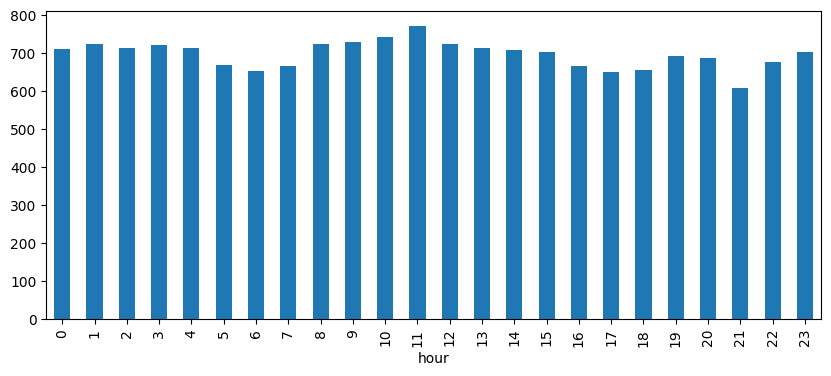

In [ ]:
train["hour"] = train["SCHED_TIME_UTC_mvt"].dt.hour

train.groupby("hour")["TAXITIME_SEC_mvt"].median().plot(
    kind="bar",
    figsize=(10,4)
)

##PHASE別の結果を数値で確認

In [ ]:
train.groupby("PHASE_mvt")["TAXITIME_SEC_mvt"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
PHASE_mvt,,,,,
ARR,2082749,536.707998,480.0,-2652.0,604797.0
DEP,2085047,991.200707,912.0,-12.0,131167.0


#DEP/ARRを確認

In [ ]:
pd.crosstab(
    train["PHASE_mvt"],
    train["TAXITIME_SEC_mvt"] < 0
)

TAXITIME_SEC_mvt,False,True
PHASE_mvt,,
ARR,2082530,220
DEP,2084678,369


In [ ]:
pd.crosstab(
    train["PHASE_mvt"],
    train["TAXITIME_SEC_mvt"] > 3600
)

TAXITIME_SEC_mvt,False,True
PHASE_mvt,,
ARR,2082310,440
DEP,2080921,4126


##TAXITIME_SEC_mvtの計算方法を確認

In [ ]:
sample = train[
    ["PHASE_mvt",
     "MVT_TIME_UTC_mvt",
     "BLOCK_TIME_UTC_mvt",
     "SCHED_TIME_UTC_mvt",
     "TAXITIME_SEC_mvt"]
].head(20)

display(sample)

,PHASE_mvt,MVT_TIME_UTC_mvt,BLOCK_TIME_UTC_mvt,SCHED_TIME_UTC_mvt,TAXITIME_SEC_mvt
0,DEP,2025-09-01 19:44:54+00:00,2025-09-01 19:31:22+00:00,2025-09-01 19:35:00+00:00,812.0
1,ARR,2025-09-01 19:47:20+00:00,2025-09-01 19:52:23+00:00,2025-09-01 19:00:00+00:00,303.0
2,DEP,2025-09-01 19:49:04+00:00,2025-09-01 19:36:27+00:00,2025-09-01 19:20:00+00:00,757.0
3,ARR,2025-09-01 19:49:54+00:00,2025-09-01 19:57:07+00:00,2025-09-01 20:00:00+00:00,433.0
4,DEP,2025-09-01 19:50:49+00:00,2025-09-01 19:38:42+00:00,2025-09-01 19:00:00+00:00,727.0
5,DEP,2025-09-01 19:50:50+00:00,2025-09-01 19:40:51+00:00,2025-09-01 19:10:00+00:00,599.0
6,DEP,2025-09-01 19:52:25+00:00,2025-09-01 19:39:36+00:00,2025-09-01 19:30:00+00:00,769.0
7,DEP,2025-09-01 19:53:21+00:00,2025-09-01 19:44:05+00:00,2025-09-01 19:35:00+00:00,556.0
8,DEP,2025-09-01 19:54:33+00:00,2025-09-01 19:39:42+00:00,2025-09-01 18:45:00+00:00,891.0
9,DEP,2025-09-01 19:54:40+00:00,2025-09-01 19:46:39+00:00,2025-09-01 19:15:00+00:00,481.0


In [ ]:
print(train.groupby("PHASE_mvt")["TAXITIME_SEC_mvt"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2).to_string())

             count    mean  median     min       max
PHASE_mvt                                           
ARR        2082749  536.71   480.0 -2652.0  604797.0
DEP        2085047  991.20   912.0   -12.0  131167.0


In [ ]:
print(pd.crosstab(
    train["PHASE_mvt"],
    train["TAXITIME_SEC_mvt"] < 0
).to_string())

print()

print(pd.crosstab(
    train["PHASE_mvt"],
    train["TAXITIME_SEC_mvt"] > 3600
).to_string())

TAXITIME_SEC_mvt    False  True 
PHASE_mvt                       
ARR               2082530    220
DEP               2084678    369

TAXITIME_SEC_mvt    False  True 
PHASE_mvt                       
ARR               2082310    440
DEP               2080921   4126


In [ ]:
print(train[
    ["PHASE_mvt",
     "MVT_TIME_UTC_mvt",
     "BLOCK_TIME_UTC_mvt",
     "SCHED_TIME_UTC_mvt",
     "TAXITIME_SEC_mvt"]
].head(20).to_string(index=False))

PHASE_mvt          MVT_TIME_UTC_mvt        BLOCK_TIME_UTC_mvt        SCHED_TIME_UTC_mvt  TAXITIME_SEC_mvt
      DEP 2025-09-01 19:44:54+00:00 2025-09-01 19:31:22+00:00 2025-09-01 19:35:00+00:00             812.0
      ARR 2025-09-01 19:47:20+00:00 2025-09-01 19:52:23+00:00 2025-09-01 19:00:00+00:00             303.0
      DEP 2025-09-01 19:49:04+00:00 2025-09-01 19:36:27+00:00 2025-09-01 19:20:00+00:00             757.0
      ARR 2025-09-01 19:49:54+00:00 2025-09-01 19:57:07+00:00 2025-09-01 20:00:00+00:00             433.0
      DEP 2025-09-01 19:50:49+00:00 2025-09-01 19:38:42+00:00 2025-09-01 19:00:00+00:00             727.0
      DEP 2025-09-01 19:50:50+00:00 2025-09-01 19:40:51+00:00 2025-09-01 19:10:00+00:00             599.0
      DEP 2025-09-01 19:52:25+00:00 2025-09-01 19:39:36+00:00 2025-09-01 19:30:00+00:00             769.0
      DEP 2025-09-01 19:53:21+00:00 2025-09-01 19:44:05+00:00 2025-09-01 19:35:00+00:00             556.0
      DEP 2025-09-01 19:54:33+00:00 2025-09-01

#DEPを対象に分析

In [ ]:
train_dep = train[train["PHASE_mvt"] == "DEP"].copy()
y = train_dep["TAXITIME_SEC_mvt"]

(2085047, 31)
count    2.085047e+06
mean     9.912007e+02
std      5.463598e+02
min     -1.200000e+01
25%      7.190000e+02
50%      9.120000e+02
75%      1.188000e+03
max      1.311670e+05
Name: TAXITIME_SEC_mvt, dtype: float64


<Axes: ylabel='Frequency'>

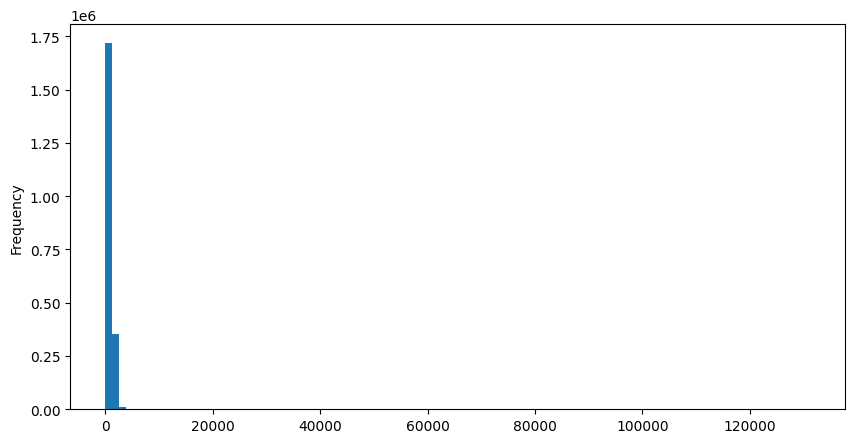

In [ ]:
train_dep = train[train["PHASE_mvt"] == "DEP"].copy()

print(train_dep.shape)
print(train_dep["TAXITIME_SEC_mvt"].describe())

train_dep["TAXITIME_SEC_mvt"].plot(
    kind="hist",
    bins=100,
    figsize=(10, 5)
)

<Axes: ylabel='Frequency'>

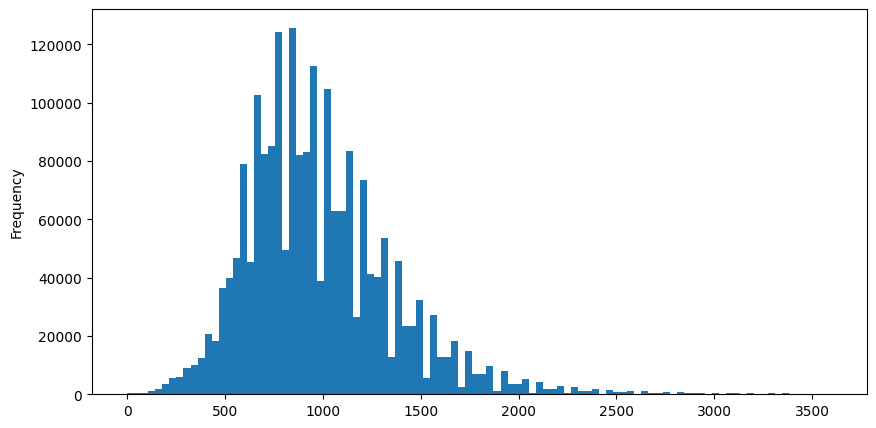

In [ ]:
train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600)
]["TAXITIME_SEC_mvt"].plot(
    kind="hist",
    bins=100,
    figsize=(10, 5)
)

#外れ値/異常値確認

In [ ]:
# 3,600秒（1時間）を超えるデータ
outlier = train_dep[
    train_dep["TAXITIME_SEC_mvt"] > 3600
]

print(outlier.shape)

outlier[
    [
        "MVT_ID_mvt",
        "PHASE_mvt",
        "ADEP_mvt",
        "ADES_mvt",
        "MVT_TIME_UTC_mvt",
        "BLOCK_TIME_UTC_mvt",
        "TAXITIME_SEC_mvt"
    ]
].head(20)

(4126, 31)


,MVT_ID_mvt,PHASE_mvt,ADEP_mvt,ADES_mvt,MVT_TIME_UTC_mvt,BLOCK_TIME_UTC_mvt,TAXITIME_SEC_mvt
25236,195776862.0,DEP,EDDF,KEWR,2025-09-20 10:45:24+00:00,2025-09-20 09:45:23+00:00,3601.0
34229,195779218.0,DEP,EDDF,LFPG,2025-09-24 05:34:49+00:00,2025-09-24 04:31:31+00:00,3798.0
38551,195776654.0,DEP,EDDF,LOWW,2025-09-23 08:28:11+00:00,2025-09-23 07:26:47+00:00,3684.0
51808,196022529.0,DEP,EDDM,LLBG,2025-09-06 10:39:00+00:00,2025-09-06 09:37:59+00:00,3661.0
52072,196023671.0,DEP,EDDM,EBLG,2025-09-08 21:28:06+00:00,2025-09-08 20:14:54+00:00,4392.0
52147,196022528.0,DEP,EDDM,RJTT,2025-09-06 10:43:58+00:00,2025-09-06 09:36:02+00:00,4076.0
55653,196022625.0,DEP,EDDM,HEGN,2025-09-06 20:35:56+00:00,2025-09-06 19:07:04+00:00,5332.0
56163,196021551.0,DEP,EDDM,OOMS,2025-09-04 21:04:01+00:00,2025-09-04 19:39:59+00:00,5042.0
56164,196021518.0,DEP,EDDM,EHAM,2025-09-04 21:08:05+00:00,2025-09-04 19:23:55+00:00,6250.0
56167,196021542.0,DEP,EDDM,EDDF,2025-09-04 21:15:06+00:00,2025-09-04 19:24:54+00:00,6612.0


In [ ]:
# 10,800秒（3時間）を超えるもの
train_dep[
    train_dep["TAXITIME_SEC_mvt"] > 10800
][
    [
        "MVT_ID_mvt",
        "ADEP_mvt",
        "MVT_TIME_UTC_mvt",
        "BLOCK_TIME_UTC_mvt",
        "TAXITIME_SEC_mvt"
    ]
].sort_values(
    "TAXITIME_SEC_mvt",
    ascending=False
).head(20)

,MVT_ID_mvt,ADEP_mvt,MVT_TIME_UTC_mvt,BLOCK_TIME_UTC_mvt,TAXITIME_SEC_mvt
977034,183903219.0,LIRF,2025-02-11 17:51:03+00:00,2025-02-10 05:24:56+00:00,131167.0
1668022,190199540.0,LIRF,2025-06-25 16:03:06+00:00,2025-06-24 15:29:54+00:00,88392.0
4087153,192626268.0,LIRF,2025-07-21 08:28:56+00:00,2025-07-20 08:00:04+00:00,88132.0
2007369,201198951.0,LIRF,2025-12-28 18:35:02+00:00,2025-12-27 18:14:57+00:00,87605.0
2337680,200300302.0,LIRF,2025-11-12 12:14:59+00:00,2025-11-11 11:55:01+00:00,87598.0
291327,196129531.0,LIRF,2025-09-28 22:38:01+00:00,2025-09-27 22:18:58+00:00,87543.0
2324742,200297323.0,LIRF,2025-11-04 13:22:00+00:00,2025-11-03 13:04:00+00:00,87480.0
4064198,192615553.0,LIRF,2025-07-03 17:01:00+00:00,2025-07-02 16:44:59+00:00,87361.0
3720076,188253302.0,LSZH,2025-05-14 14:55:39+00:00,2025-05-13 14:39:58+00:00,87341.0
3347748,185042445.0,LIRF,2025-03-28 10:41:03+00:00,2025-03-27 10:26:56+00:00,87247.0


In [ ]:
train_dep[
    train_dep["TAXITIME_SEC_mvt"] < 0
][
    [
        "MVT_ID_mvt",
        "ADEP_mvt",
        "MVT_TIME_UTC_mvt",
        "BLOCK_TIME_UTC_mvt",
        "TAXITIME_SEC_mvt"
    ]
]

,MVT_ID_mvt,ADEP_mvt,MVT_TIME_UTC_mvt,BLOCK_TIME_UTC_mvt,TAXITIME_SEC_mvt
224513,196062658.0,LFPG,2025-09-03 06:05:55+00:00,2025-09-03 06:06:04+00:00,-9.0
246267,196053775.0,LFPG,2025-09-18 12:15:59+00:00,2025-09-18 12:16:00+00:00,-1.0
296026,196149977.0,LSZH,2025-09-05 13:42:49+00:00,2025-09-05 13:42:53+00:00,-4.0
296832,196148715.0,LSZH,2025-09-02 06:36:16+00:00,2025-09-02 06:36:20+00:00,-4.0
297451,196148201.0,LSZH,2025-09-01 09:38:35+00:00,2025-09-01 09:38:43+00:00,-8.0
...,...,...,...,...,...
4113758,193390852.0,LSZH,2025-07-22 09:25:34+00:00,2025-07-22 09:25:35+00:00,-1.0
4114037,193388148.0,LSZH,2025-07-20 14:28:49+00:00,2025-07-20 14:28:55+00:00,-6.0
4114544,193386331.0,LSZH,2025-07-23 15:20:07+00:00,2025-07-23 15:20:09+00:00,-2.0
4115613,193390225.0,LSZH,2025-07-18 06:33:55+00:00,2025-07-18 06:34:04+00:00,-9.0


count    2.080552e+06
mean     9.813278e+02
std      3.880163e+02
min      0.000000e+00
25%      7.190000e+02
50%      9.110000e+02
75%      1.184000e+03
max      3.600000e+03
Name: TAXITIME_SEC_mvt, dtype: float64


<Axes: ylabel='Frequency'>

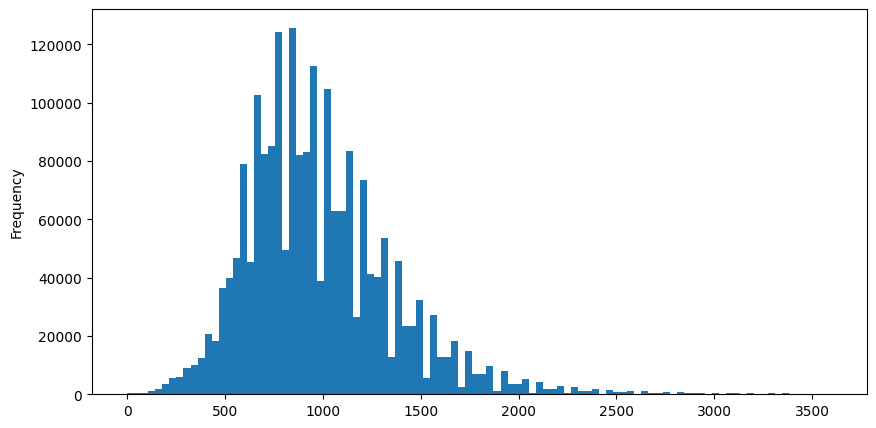

In [ ]:
train_dep_clean = train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600)
].copy()

print(train_dep_clean["TAXITIME_SEC_mvt"].describe())

train_dep_clean["TAXITIME_SEC_mvt"].plot(
    kind="hist",
    bins=100,
    figsize=(10,5)
)

#EDA

##空港別

In [ ]:
# 空港別のTaxi-out time
airport_stats = train_dep.groupby(
    "ADEP_mvt"
)["TAXITIME_SEC_mvt"].agg(
    count="count",
    mean="mean",
    median="median"
).sort_values(
    "count",
    ascending=False
)

# データ数が多い空港
print(airport_stats.head(20))

# 中央値が長い空港
print(
    airport_stats
    .sort_values("median", ascending=False)
    .head(20)
)

           count         mean  median
ADEP_mvt                             
LTFM      272965  1052.952269   963.0
EHAM      247951   784.559748   742.0
LFPG      239552  1019.523310   954.0
EGLL      239546  1364.239319  1319.0
EDDF      230141   863.478155   837.0
LEMD      212242  1014.709982   985.0
LEBL      179705   956.549356   906.0
EDDM      167334   811.911889   774.0
LIRF      160704  1194.607527  1025.0
LSZH      134907   740.513650   711.0
           count         mean  median
ADEP_mvt                             
EGLL      239546  1364.239319  1319.0
LIRF      160704  1194.607527  1025.0
LEMD      212242  1014.709982   985.0
LTFM      272965  1052.952269   963.0
LFPG      239552  1019.523310   954.0
LEBL      179705   956.549356   906.0
EDDF      230141   863.478155   837.0
EDDM      167334   811.911889   774.0
EHAM      247951   784.559748   742.0
LSZH      134907   740.513650   711.0


In [ ]:
target = train_dep["TAXITIME_SEC_mvt"]

print("DEPの総件数:", target.notna().sum())
print("負の値:", (target < 0).sum())
print("1時間超:", (target > 3600).sum())
print("3時間超:", (target > 10800).sum())

print("\n外れ値を除いたデータの統計量")
print(train_dep_clean["TAXITIME_SEC_mvt"].describe())

DEPの総件数: 2085047
負の値: 369
1時間超: 4126
3時間超: 202

外れ値を除いたデータの統計量
count    2.080552e+06
mean     9.813278e+02
std      3.880163e+02
min      0.000000e+00
25%      7.190000e+02
50%      9.110000e+02
75%      1.184000e+03
max      3.600000e+03
Name: TAXITIME_SEC_mvt, dtype: float64


In [ ]:
print(
    airport_stats
    .head(20)
    .round(1)
    .to_string()
)

           count    mean  median
ADEP_mvt                        
LTFM      272965  1053.0   963.0
EHAM      247951   784.6   742.0
LFPG      239552  1019.5   954.0
EGLL      239546  1364.2  1319.0
EDDF      230141   863.5   837.0
LEMD      212242  1014.7   985.0
LEBL      179705   956.5   906.0
EDDM      167334   811.9   774.0
LIRF      160704  1194.6  1025.0
LSZH      134907   740.5   711.0


In [ ]:
airport_stats_filtered = airport_stats[
    airport_stats["count"] >= 1000
]

print(
    airport_stats_filtered
    .sort_values("median", ascending=False)
    .head(20)
    .round(1)
    .to_string()
)

           count    mean  median
ADEP_mvt                        
EGLL      239546  1364.2  1319.0
LIRF      160704  1194.6  1025.0
LEMD      212242  1014.7   985.0
LTFM      272965  1053.0   963.0
LFPG      239552  1019.5   954.0
LEBL      179705   956.5   906.0
EDDF      230141   863.5   837.0
EDDM      167334   811.9   774.0
EHAM      247951   784.6   742.0
LSZH      134907   740.5   711.0


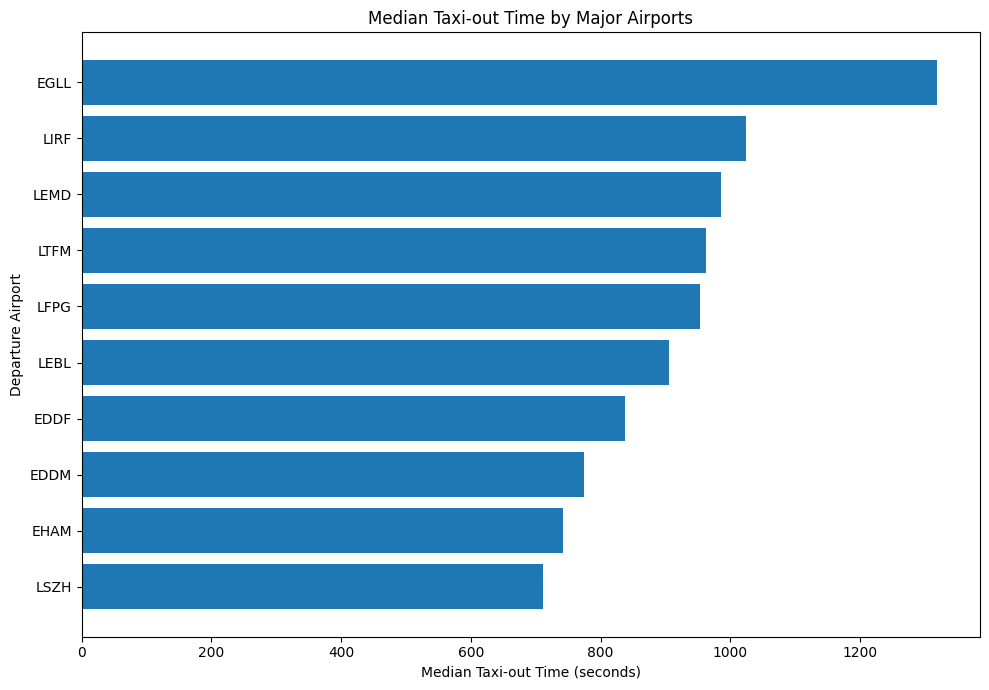

In [ ]:
import matplotlib.pyplot as plt

top_airports = airport_stats_filtered.sort_values(
    "count",
    ascending=False
).head(20)

top_airports = top_airports.sort_values("median")

plt.figure(figsize=(10, 7))

plt.barh(
    top_airports.index,
    top_airports["median"]
)

plt.xlabel("Median Taxi-out Time (seconds)")
plt.ylabel("Departure Airport")
plt.title("Median Taxi-out Time by Major Airports")

plt.tight_layout()
plt.show()

出発空港別に比較したところ、Taxi-out timeには大きな差が見られた。中央値はEGLLで1319秒と最も長く、LSZHでは711秒と最も短かった。このことから、出発空港はTaxi-out timeを左右する重要な要因の一つと考えられる。

##曜日別

In [ ]:
# 曜日を作成
train_dep["weekday"] = train_dep[
    "MVT_TIME_UTC_mvt"
].dt.dayofweek

weekday_stats = train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600)
].groupby(
    "weekday"
)["TAXITIME_SEC_mvt"].agg(
    count="count",
    mean="mean",
    median="median"
)

# 曜日名に変更
weekday_stats.index = [
    "Mon", "Tue", "Wed",
    "Thu", "Fri", "Sat", "Sun"
]

print(weekday_stats.round(1))

      count   mean  median
Mon  300252  984.7   917.0
Tue  289873  967.8   905.0
Wed  298661  975.7   909.0
Thu  298823  980.7   911.0
Fri  307136  994.2   932.0
Sat  285218  975.0   907.0
Sun  300589  990.1   921.0


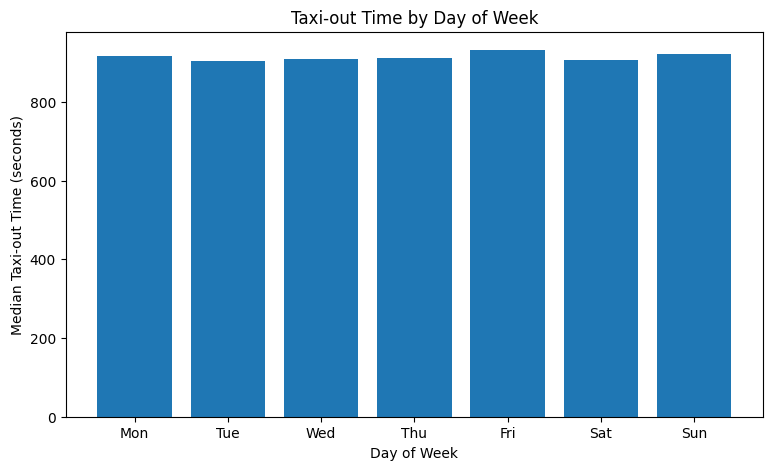

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    weekday_stats.index,
    weekday_stats["median"]
)

plt.xlabel("Day of Week")
plt.ylabel("Median Taxi-out Time (seconds)")
plt.title("Taxi-out Time by Day of Week")

plt.show()

曜日別に比較したところ、金曜日のTaxi-out timeが最も長く、火曜日が最も短かった。ただし、曜日間の中央値の差は27秒程度であり、出発空港による差と比較すると小さいことが分かった。そのため、曜日はTaxi-out timeに影響する可能性はあるものの、主要な要因ではないと考えられる。

##月別

In [ ]:
# 月を作成
train_dep["month"] = train_dep[
    "MVT_TIME_UTC_mvt"
].dt.month

month_stats = train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600)
].groupby(
    "month"
)["TAXITIME_SEC_mvt"].agg(
    count="count",
    mean="mean",
    median="median"
)

print(month_stats.round(1))

        count    mean  median
month                        
1      153335   985.4   906.0
2      142935   980.7   903.0
3      164266   967.0   905.0
4      175086   966.6   908.0
5      184962   980.6   924.0
6      182688   962.3   902.0
7      190023  1005.8   946.0
8      190801   983.8   928.0
9      183628   980.3   913.0
10     185341   984.6   924.0
11     162092   990.4   925.0
12     165395   987.3   911.0


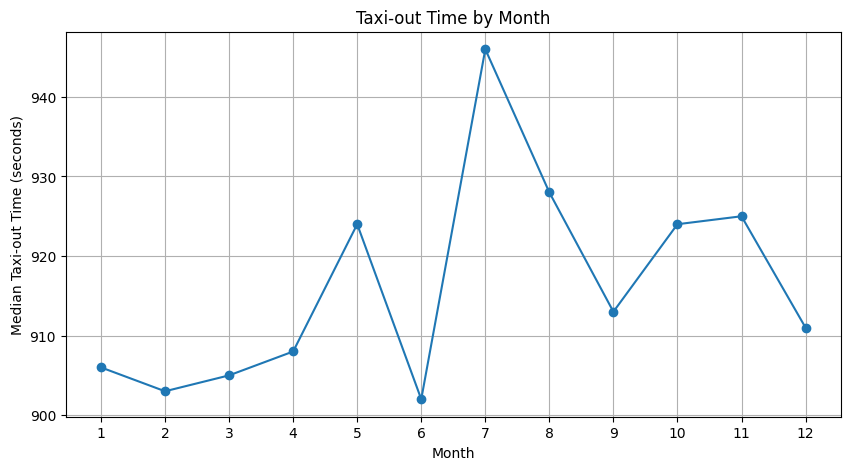

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    month_stats.index,
    month_stats["median"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Median Taxi-out Time (seconds)")
plt.title("Taxi-out Time by Month")

plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

月別では7月のTaxi-out timeが最も長く、6月が最も短かった。月による差は見られるものの、空港別の差ほど大きくなかった。


##空港×時間帯

In [ ]:
major_airports = [
    "LTFM", "EHAM", "LFPG", "EGLL", "EDDF",
    "LEMD", "LEBL", "EDDM", "LIRF", "LSZH"
]

In [ ]:
airport_hour_stats = train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600) &
    (train_dep["ADEP_mvt"].isin(major_airports))
].groupby(
    ["ADEP_mvt", "hour"]
)["TAXITIME_SEC_mvt"].median().unstack()

print(
    airport_hour_stats.round(0)
)

hour          0       1       2       3      4       5       6       7   \
ADEP_mvt                                                                  
EDDF       504.0   381.0   938.0   845.0  732.0   713.0   768.0   759.0   
EDDM       371.0   364.0   363.0   780.0  768.0   769.0   718.0   789.0   
EGLL         NaN     NaN     NaN     NaN    NaN  1022.0  1075.0  1147.0   
EHAM       626.0   928.0   793.0   599.0  599.0   690.0   694.0   689.0   
LEBL       753.0   657.0   641.0   780.0  783.0   828.0   887.0  1026.0   
LEMD       986.0   891.0   913.0  1000.0  933.0   945.0   972.0  1000.0   
LFPG       911.0  1084.0  1092.0   953.0  773.0   846.0   899.0   958.0   
LIRF      1013.0  1021.0  1192.0  1069.0  969.0   965.0   851.0  1084.0   
LSZH         NaN     NaN    14.0   626.0  670.0   734.0   695.0   689.0   
LTFM       834.0   900.0   898.0   851.0  970.0  1072.0   959.0   902.0   

hour          8       9   ...      14      15      16      17      18      19  \
ADEP_mvt          

In [ ]:
airport_hour_count = train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600) &
    (train_dep["ADEP_mvt"].isin(major_airports))
].groupby(
    ["ADEP_mvt", "hour"]
)["TAXITIME_SEC_mvt"].count().unstack()

print(
    airport_hour_count
    .round(0)
    .to_string()
)

hour          0       1       2        3        4        5        6        7        8        9        10       11       12       13       14       15       16       17       18       19       20      21       22      23
ADEP_mvt                                                                                                                                                                                                                   
EDDF         2.0     2.0  1251.0   1719.0   5024.0   9028.0  10812.0  15402.0  18343.0  17990.0  18077.0  20124.0  14721.0  10039.0  13421.0  13094.0   9365.0   6815.0  11938.0  16890.0  13294.0  2700.0     16.0     1.0
EDDM         7.0     8.0    11.0   1021.0   4690.0   5447.0  12006.0  10604.0  10472.0  15422.0  14150.0   8066.0   8453.0  14255.0  11431.0   6177.0   6971.0   9068.0   8293.0   8628.0   8972.0  2892.0    220.0    11.0
EGLL         NaN     NaN     NaN      NaN      NaN   5383.0  12124.0  14766.0  16195.0  14736.0  15589.0  15542.0  14928

空港×時間帯別に分析した結果、Taxi-out timeは空港だけでなく時間帯によっても大きく異なることが分かった。特にEGLLでは14～16時頃に約1,400秒と長くなる一方、LSZHなどでは600～700秒程度の時間帯も見られた。このことから、Taxi-out timeの予測には空港と時間帯を組み合わせて考慮することが重要であると考えられる。ただし、深夜など件数が少ない時間帯については、中央値の解釈に注意が必要である。


##滑走路別

In [ ]:
runway_stats = train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600)
].groupby(
    "RUNWAY_mvt"
)["TAXITIME_SEC_mvt"].agg(
    count="count",
    mean="mean",
    median="median"
).sort_values(
    "count",
    ascending=False
)

print(
    runway_stats
    .head(20)
    .round(1)
    .to_string()
)

             count    mean  median
RUNWAY_mvt                        
18          171635   930.4   914.0
25          143007  1083.8  1011.0
36L         142773   998.7   972.0
36          126096   926.6   891.0
24L         124511   960.3   914.0
09R         119370  1260.7  1209.0
26R         110953   929.5   845.0
08L         108317   920.9   844.0
27L         101387  1251.3  1203.0
27R          98212  1324.3  1269.0
24           85212   665.3   627.0
36R          84705  1078.4  1050.0
28           84687   689.6   673.0
35L          79631  1081.6  1011.0
26L          58005   761.3   720.0
18L          55572   734.7   701.0
06R          52346   939.9   876.0
25C          46007   787.5   735.0
07C          43195   816.3   776.0
08R          37294   900.7   847.0


滑走路別に分析した結果、Taxi-out timeには滑走路によって大きな差が見られた。中央値は27Rで1269秒と最も長く、24では627秒と最も短かった。最も長い滑走路と短い滑走路では約10分の差があり、滑走路がTaxi-out timeに影響する可能性が示された。また、滑走路は空港ごとに利用状況や混雑状況が異なるため、空港と滑走路を組み合わせて分析することが重要だと考えられる。

##空港×滑走路

In [ ]:
airport_runway_stats = train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600)
].groupby(
    ["ADEP_mvt", "RUNWAY_mvt"]
)["TAXITIME_SEC_mvt"].agg(
    count="count",
    mean="mean",
    median="median"
).sort_values(
    "count",
    ascending=False
)

print(
    airport_runway_stats
    .head(30)
    .round(1)
    .to_string()
)

                      count    mean  median
ADEP_mvt RUNWAY_mvt                        
LIRF     25          143007  1083.8  1011.0
EDDF     18          139980   901.1   887.0
LTFM     36          126096   926.6   891.0
LEBL     24L         124511   960.3   914.0
EGLL     09R          87389  1330.2  1310.0
EHAM     24           85212   665.3   627.0
LEMD     36R          84705  1078.4  1050.0
LSZH     28           84687   689.6   673.0
LEMD     36L          84203   940.9   903.0
LTFM     35L          79631  1081.6  1011.0
EGLL     27R          76739  1387.5  1332.0
LFPG     08L          75084   975.9   902.0
EGLL     27L          74581  1347.7  1316.0
LFPG     26R          71777   993.3   906.0
EHAM     36L          58570  1081.8  1049.0
EDDM     26L          57778   760.0   719.0
EHAM     18L          55571   734.7   701.0
LEBL     06R          52346   939.9   876.0
EDDF     25C          46007   787.5   735.0
         07C          43195   816.3   776.0
EDDM     26R          39176   81

空港と滑走路を組み合わせて分析した結果、Taxi-out timeは空港だけでなく、空港と滑走路の組み合わせによっても大きく異なることが分かった。特にEGLLでは、27R、27L、09Rのいずれも中央値が約1,300秒と長かった。一方、EHAM 24では627秒、LSZH 28では673秒と短かった。また、同じ空港内でも滑走路によってTaxi-out timeに差が見られた。このことから、Taxi-out timeの予測では空港と滑走路をそれぞれ考慮することが重要だと考えられる。


##まとめ

空港 ＞ 時間帯 ＞ 滑走路 ＞ 曜日・月

というように、特に空港・時間帯・滑走路でTaxi-out timeの違いが確認できた。

##モデル作成

In [ ]:
model_data = train_dep[
    (train_dep["TAXITIME_SEC_mvt"] >= 0) &
    (train_dep["TAXITIME_SEC_mvt"] <= 3600)
].copy()

model_data["hour"] = model_data["MVT_TIME_UTC_mvt"].dt.hour
model_data["month"] = model_data["MVT_TIME_UTC_mvt"].dt.month
model_data["weekday"] = model_data["MVT_TIME_UTC_mvt"].dt.dayofweek

print(model_data.shape)

(2080552, 33)


In [ ]:
#日付確認
print(model_data["MVT_TIME_UTC_mvt"].min())
print(model_data["MVT_TIME_UTC_mvt"].max())

2025-01-01 00:05:56+00:00
2025-12-31 23:57:36+00:00


#学習用/検証用に時系列分割


In [ ]:
# 2025年1～9月を学習、10～12月を検証
train_model = model_data[
    model_data["MVT_TIME_UTC_mvt"] < "2025-10-01"
].copy()

valid_model = model_data[
    model_data["MVT_TIME_UTC_mvt"] >= "2025-10-01"
].copy()

print("学習:", train_model.shape)
print("検証:", valid_model.shape)

学習: (1567724, 33)
検証: (512828, 33)


In [ ]:
# まず使う特徴量
features = [
    "ADEP_mvt",
    "hour",
    "month",
    "weekday",
    "RUNWAY_mvt"
]

target = "TAXITIME_SEC_mvt"

#CatBoostでモデル構築

In [ ]:
# CatBoostインストール
!pip install catboost -q

In [ ]:
# 学習に使う変数を指定
features = [
    "ADEP_mvt",
    "hour",
    "month",
    "weekday",
    "RUNWAY_mvt"
]

target = "TAXITIME_SEC_mvt"

X_train = train_model[features].copy()
y_train = train_model[target]

X_valid = valid_model[features].copy()
y_valid = valid_model[target]

In [ ]:
# 欠損値確認
print(X_train.isnull().sum())
print(X_valid.isnull().sum())

ADEP_mvt      0
hour          0
month         0
weekday       0
RUNWAY_mvt    0
dtype: int64
ADEP_mvt      0
hour          0
month         0
weekday       0
RUNWAY_mvt    0
dtype: int64


In [ ]:
# カテゴリ変数指定
cat_features = [
    "ADEP_mvt",
    "RUNWAY_mvt"
]

##基本の特徴量

In [ ]:
# CatBoostを学習
from catboost import CatBoostRegressor

model = CatBoostRegressor(
    iterations=500,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    eval_metric="RMSE",
    verbose=100,
    random_seed=42
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=50
)

0:	learn: 379.5535113	test: 380.6630670	best: 380.6630670 (0)	total: 290ms	remaining: 2m 24s
100:	learn: 319.2319271	test: 331.0341487	best: 331.0338559 (83)	total: 21.2s	remaining: 1m 23s
200:	learn: 316.2722100	test: 330.7800384	best: 330.6803895 (175)	total: 46.7s	remaining: 1m 9s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 330.6803895
bestIteration = 175

Shrink model to first 176 iterations.


CatBoostRegressor(depth=8, eval_metric='RMSE', iterations=500, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=100)

In [ ]:
# RMSEを計算
from sklearn.metrics import mean_squared_error
import numpy as np

pred = model.predict(X_valid)

rmse = np.sqrt(
    mean_squared_error(y_valid, pred)
)

print("Validation RMSE:", rmse)

Validation RMSE: 330.6803895189306


約330.68秒

In [ ]:
# 時刻を細かく
model_data["minute"] = model_data["MVT_TIME_UTC_mvt"].dt.minute

#特徴量を比較

##model1 空港×滑走路を追加

In [ ]:
train_model["airport_runway"] = (
    train_model["ADEP_mvt"].astype(str)
    + "_"
    + train_model["RUNWAY_mvt"].astype(str)
)

valid_model["airport_runway"] = (
    valid_model["ADEP_mvt"].astype(str)
    + "_"
    + valid_model["RUNWAY_mvt"].astype(str)
)

In [ ]:
features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "hour",
    "month",
    "weekday",
    "airport_runway"
]

cat_features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "airport_runway"
]

X_train = train_model[features]
X_valid = valid_model[features]

model1 = CatBoostRegressor(
    iterations=500,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    eval_metric="RMSE",
    verbose=100,
    random_seed=42
)

model1.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=50
)

pred1 = model1.predict(X_valid)

rmse1 = np.sqrt(mean_squared_error(y_valid, pred1))

print("model1 RMSE:", rmse1)

0:	learn: 378.3005017	test: 379.6298598	best: 379.6298598 (0)	total: 407ms	remaining: 3m 22s
100:	learn: 319.1598610	test: 330.6863417	best: 330.6088133 (84)	total: 28.1s	remaining: 1m 51s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 330.6088133
bestIteration = 84

Shrink model to first 85 iterations.
model1 RMSE: 330.6088132818734


約330.61秒

##model2 出発時刻を追加

In [ ]:
train_model["sched_hour"] = train_model["SCHED_TIME_UTC_mvt"].dt.hour
train_model["sched_minute"] = train_model["SCHED_TIME_UTC_mvt"].dt.minute

valid_model["sched_hour"] = valid_model["SCHED_TIME_UTC_mvt"].dt.hour
valid_model["sched_minute"] = valid_model["SCHED_TIME_UTC_mvt"].dt.minute

In [ ]:
features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "hour",
    "month",
    "weekday",
    "sched_hour",
    "sched_minute"
]

cat_features = [
    "ADEP_mvt",
    "RUNWAY_mvt"
]

X_train = train_model[features]
X_valid = valid_model[features]

model2 = CatBoostRegressor(
    iterations=500,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    eval_metric="RMSE",
    verbose=100,
    random_seed=42
)

model2.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=50
)

pred2 = model2.predict(X_valid)

rmse2 = np.sqrt(mean_squared_error(y_valid, pred2))

print("model2 RMSE:", rmse2)

0:	learn: 379.7269238	test: 381.1072298	best: 381.1072298 (0)	total: 323ms	remaining: 2m 41s
100:	learn: 313.9494492	test: 324.7524545	best: 324.7524545 (100)	total: 35.7s	remaining: 2m 21s
200:	learn: 308.5157887	test: 321.2713126	best: 321.2713126 (200)	total: 1m 13s	remaining: 1m 48s
300:	learn: 305.4356645	test: 320.2596745	best: 320.2379571 (299)	total: 1m 45s	remaining: 1m 9s
400:	learn: 303.5990533	test: 319.8283396	best: 319.8283396 (400)	total: 2m 12s	remaining: 32.7s
499:	learn: 302.1698578	test: 319.6461778	best: 319.6461778 (499)	total: 2m 39s	remaining: 0us

bestTest = 319.6461778
bestIteration = 499

model2 RMSE: 319.6461777654751


約319.65秒

##model3 空港×時間帯を追加

In [ ]:
train_model["airport_hour"] = (
    train_model["ADEP_mvt"].astype(str)
    + "_"
    + train_model["hour"].astype(str)
)

valid_model["airport_hour"] = (
    valid_model["ADEP_mvt"].astype(str)
    + "_"
    + valid_model["hour"].astype(str)
)

features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "hour",
    "month",
    "weekday",
    "sched_hour",
    "sched_minute",
    "airport_hour"
]

cat_features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "airport_hour"
]

X_train = train_model[features]
X_valid = valid_model[features]

model3 = CatBoostRegressor(
    iterations=500,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    eval_metric="RMSE",
    verbose=100,
    random_seed=42
)

model3.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=50
)

pred3 = model3.predict(X_valid)

rmse3 = np.sqrt(mean_squared_error(y_valid, pred3))

print("model3 RMSE:", rmse3)

0:	learn: 377.4318985	test: 378.5216361	best: 378.5216361 (0)	total: 407ms	remaining: 3m 23s
100:	learn: 312.2215991	test: 325.1146429	best: 325.1146429 (100)	total: 31.7s	remaining: 2m 5s
200:	learn: 307.1319334	test: 321.8855108	best: 321.8855108 (200)	total: 1m 8s	remaining: 1m 41s
300:	learn: 304.4749426	test: 320.9591156	best: 320.9376857 (297)	total: 1m 43s	remaining: 1m 8s
400:	learn: 302.6186576	test: 320.7357055	best: 320.6982116 (386)	total: 2m 18s	remaining: 34.1s


約320.64秒

##model4 空港×時間帯の件数を追加

In [ ]:
airport_hour_count = (
    train_model
    .groupby(["ADEP_mvt", "hour"])
    .size()
    .reset_index(name="airport_hour_count")
)

train_model = train_model.merge(
    airport_hour_count,
    on=["ADEP_mvt", "hour"],
    how="left"
)

valid_model = valid_model.merge(
    airport_hour_count,
    on=["ADEP_mvt", "hour"],
    how="left"
)

In [ ]:
features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "hour",
    "month",
    "weekday",
    "sched_hour",
    "sched_minute",
    "airport_hour_count"
]

cat_features = [
    "ADEP_mvt",
    "RUNWAY_mvt"
]

X_train = train_model[features]
X_valid = valid_model[features]

model4 = CatBoostRegressor(
    iterations=500,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    eval_metric="RMSE",
    verbose=100,
    random_seed=42
)

model4.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=50
)

pred4 = model4.predict(X_valid)

rmse4 = np.sqrt(mean_squared_error(y_valid, pred4))

print("model4 RMSE:", rmse4)

約320.29秒

##model5 空港ごとの混雑度

In [ ]:
airport_count = (
    train_model
    .groupby("ADEP_mvt")
    .size()
    .reset_index(name="airport_count")
)

print(airport_count.head())

In [ ]:
train_model = train_model.merge(
    airport_count,
    on="ADEP_mvt",
    how="left"
)

valid_model = valid_model.merge(
    airport_count,
    on="ADEP_mvt",
    how="left"
)

In [ ]:
features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "hour",
    "month",
    "weekday",
    "sched_hour",
    "sched_minute",
    "airport_count"
]

cat_features = [
    "ADEP_mvt",
    "RUNWAY_mvt"
]

X_train = train_model[features]
X_valid = valid_model[features]

y_train = train_model["TAXITIME_SEC_mvt"]
y_valid = valid_model["TAXITIME_SEC_mvt"]

model5 = CatBoostRegressor(
    iterations=1000,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    eval_metric="RMSE",
    verbose=100,
    random_seed=42
)

model5.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=50
)

pred5 = model5.predict(X_valid)

rmse5 = np.sqrt(mean_squared_error(y_valid, pred5))

print("Validation RMSE:", rmse5)

0:	learn: 379.2561682	test: 380.4924488	best: 380.4924488 (0)	total: 326ms	remaining: 5m 25s
100:	learn: 314.0186742	test: 324.8832181	best: 324.8832181 (100)	total: 25.9s	remaining: 3m 50s
200:	learn: 308.4778486	test: 321.4581484	best: 321.4581484 (200)	total: 53.9s	remaining: 3m 34s
300:	learn: 305.4281530	test: 320.2597351	best: 320.2597351 (300)	total: 1m 22s	remaining: 3m 11s
400:	learn: 303.5248108	test: 319.9313957	best: 319.8920163 (360)	total: 1m 48s	remaining: 2m 42s
500:	learn: 302.0219179	test: 319.6980925	best: 319.6606130 (492)	total: 2m 15s	remaining: 2m 14s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 319.660613
bestIteration = 492

Shrink model to first 493 iterations.
Validation RMSE: 319.66061299446966


約319.66秒

##model2 iterations を増やす


最も性能が良かったmodel2のiterations を増やす



In [ ]:
train_model["sched_hour"] = train_model["SCHED_TIME_UTC_mvt"].dt.hour
train_model["sched_minute"] = train_model["SCHED_TIME_UTC_mvt"].dt.minute

valid_model["sched_hour"] = valid_model["SCHED_TIME_UTC_mvt"].dt.hour
valid_model["sched_minute"] = valid_model["SCHED_TIME_UTC_mvt"].dt.minute

In [ ]:
features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "hour",
    "month",
    "weekday",
    "sched_hour",
    "sched_minute"
]

In [ ]:
cat_features = [
    "ADEP_mvt",
    "RUNWAY_mvt"
]

X_train = train_model[features]
X_valid = valid_model[features]

y_train = train_model["TAXITIME_SEC_mvt"]
y_valid = valid_model["TAXITIME_SEC_mvt"]

In [ ]:
model2 = CatBoostRegressor(
    iterations=1000,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    eval_metric="RMSE",
    verbose=100,
    random_seed=42
)

model2.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=50
)

pred2 = model2.predict(X_valid)

rmse2 = np.sqrt(mean_squared_error(y_valid, pred2))

print("Validation RMSE:", rmse2)

0:	learn: 379.7269238	test: 381.1072298	best: 381.1072298 (0)	total: 264ms	remaining: 4m 23s
100:	learn: 313.9494492	test: 324.7524545	best: 324.7524545 (100)	total: 25.1s	remaining: 3m 43s
200:	learn: 308.5157887	test: 321.2713126	best: 321.2713126 (200)	total: 52.4s	remaining: 3m 28s
300:	learn: 305.4356645	test: 320.2596745	best: 320.2379571 (299)	total: 1m 18s	remaining: 3m 2s
400:	learn: 303.5990533	test: 319.8283396	best: 319.8283396 (400)	total: 1m 43s	remaining: 2m 34s
500:	learn: 302.1522052	test: 319.6484401	best: 319.6461778 (499)	total: 2m 8s	remaining: 2m 7s
600:	learn: 300.9545287	test: 319.7001576	best: 319.6436261 (557)	total: 2m 33s	remaining: 1m 41s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 319.6436261
bestIteration = 557

Shrink model to first 558 iterations.
Validation RMSE: 319.6436260968585


約319.64秒

7特徴量のモデルでは、RMSEは約319.64秒となった。最も良かった学習回数は558回だった。

##どの特徴量が予測に効いているのか

In [ ]:
features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "hour",
    "month",
    "weekday",
    "sched_hour",
    "sched_minute"
]

In [ ]:
# 特徴量重要度
importance = model2.get_feature_importance()

importance_df = pd.DataFrame({
    "feature": features,
    "importance": importance
}).sort_values("importance", ascending=False)

display(importance_df)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")

plt.gca().invert_yaxis()
plt.show()

特徴量重要度を確認した結果、出発空港（26.39%）が最も重要であり、次いで滑走路（22.07%）、実際の出発時刻（19.02%）、予定出発時刻（18.02%）となった。一方、曜日の重要度は1.78%と低かった。このことから、Taxi-out timeの予測には、空港や滑走路、時間帯に関する情報が特に重要であると考えられる。


# 初期モデルの全データ学習


In [ ]:
model_data["sched_hour"] = model_data["SCHED_TIME_UTC_mvt"].dt.hour
model_data["sched_minute"] = model_data["SCHED_TIME_UTC_mvt"].dt.minute

In [ ]:
model_data["hour"] = model_data["MVT_TIME_UTC_mvt"].dt.hour
model_data["month"] = model_data["MVT_TIME_UTC_mvt"].dt.month
model_data["weekday"] = model_data["MVT_TIME_UTC_mvt"].dt.dayofweek

model_data["sched_hour"] = model_data["SCHED_TIME_UTC_mvt"].dt.hour
model_data["sched_minute"] = model_data["SCHED_TIME_UTC_mvt"].dt.minute

In [ ]:
features = [
    "ADEP_mvt",
    "RUNWAY_mvt",
    "hour",
    "month",
    "weekday",
    "sched_hour",
    "sched_minute"
]

cat_features = ["ADEP_mvt", "RUNWAY_mvt"]

X_full = model_data[features]
y_full = model_data["TAXITIME_SEC_mvt"]

final_model = CatBoostRegressor(
    iterations=557,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    verbose=100,
    random_seed=42
)

final_model.fit(
    X_full,
    y_full,
    cat_features=cat_features
)

0:	learn: 379.8929854	total: 352ms	remaining: 3m 15s
100:	learn: 315.5649406	total: 28.6s	remaining: 2m 9s
200:	learn: 310.2475082	total: 1m	remaining: 1m 47s
300:	learn: 307.4204429	total: 1m 32s	remaining: 1m 18s
400:	learn: 305.5198481	total: 2m 2s	remaining: 47.8s
500:	learn: 304.1527865	total: 2m 32s	remaining: 17s
556:	learn: 303.5375262	total: 2m 48s	remaining: 0us


CatBoostRegressor(depth=8, iterations=557, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=100)

##予測

In [ ]:
ranking = pd.read_parquet("ranking.parquet")
submitting = pd.read_parquet("submitting.parquet")

print(ranking.shape)
print(submitting.shape)

(689534, 30)
(344841, 2)


In [ ]:
test_data = ranking.merge(
    submitting[["MVT_ID_mvt"]],
    on="MVT_ID_mvt",
    how="inner"
)

test_dep = test_data[test_data["PHASE_mvt"] == "DEP"].copy()

print(test_dep.shape)

(344841, 30)


In [ ]:
test_dep["hour"] = test_dep["MVT_TIME_UTC_mvt"].dt.hour
test_dep["weekday"] = test_dep["MVT_TIME_UTC_mvt"].dt.dayofweek
test_dep["month"] = test_dep["MVT_TIME_UTC_mvt"].dt.month

test_dep["sched_hour"] = test_dep["SCHED_TIME_UTC_mvt"].dt.hour
test_dep["sched_minute"] = test_dep["SCHED_TIME_UTC_mvt"].dt.minute

X_test = test_dep[features]

pred = final_model.predict(X_test)

print(pred[:10])

[ 926.35964774 1079.18783573  882.19437994  882.19437994  770.93971853
  980.46403506  770.93971853  765.75945596  822.84906959  868.72105374]


In [ ]:
submission = submitting.copy()
submission["TAXITIME_SEC_mvt"] = pred

submission.to_csv("submission.csv", index=False)

print(submission.head())
print(submission.shape)

    MVT_ID_mvt  TAXITIME_SEC_mvt
0  202501153.0        926.359648
1  202501107.0       1079.187836
2  202501179.0        882.194380
3  202501178.0        882.194380
4  202501174.0        770.939719
(344841, 2)


In [ ]:
print(submission.isna().sum())
print(submission["TAXITIME_SEC_mvt"].describe())

MVT_ID_mvt          0
TAXITIME_SEC_mvt    0
dtype: int64
count    344841.000000
mean       1007.851974
std         238.719475
min        -292.044975
25%         847.018811
50%         981.382561
75%        1131.865953
max        2822.150489
Name: TAXITIME_SEC_mvt, dtype: float64


#parquet作成

In [ ]:
submission.to_parquet(
    "athletic-yacht_v1.parquet",
    index=False
)

In [ ]:
check = pd.read_parquet("athletic-yacht_v1.parquet")

print(check.shape)
print(check.head())
print(check.isna().sum())

(344841, 2)
    MVT_ID_mvt  TAXITIME_SEC_mvt
0  202501153.0        926.359648
1  202501107.0       1079.187836
2  202501179.0        882.194380
3  202501178.0        882.194380
4  202501174.0        770.939719
MVT_ID_mvt          0
TAXITIME_SEC_mvt    0
dtype: int64


In [ ]:
from google.colab import files

files.download("/content/athletic-yacht_v1.parquet")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#予測結果確認

In [ ]:
import os

print("Colab内のファイル一覧：")
for f in os.listdir("/content"):
    print(f)

Colab内のファイル一覧：
.config
submission.csv
training_2025-09-01_2025-10-01.parquet
training_2025-08-01_2025-09-01.parquet
final_submitting.parquet
training_2025-02-01_2025-03-01.parquet
final_ranking.parquet
training_2025-04-01_2025-05-01.parquet
training_2025-06-01_2025-07-01.parquet
training_2025-12-01_2026-01-01.parquet
training_2025-11-01_2025-12-01.parquet
catboost_info
training_2025-01-01_2025-02-01.parquet
training_2025-10-01_2025-11-01.parquet
ranking.parquet
training_2025-03-01_2025-04-01.parquet
athletic-yacht_v1.parquet
training_2025-05-01_2025-06-01.parquet
submitting.parquet
training_2025-07-01_2025-08-01.parquet
sample_data


In [ ]:

import os

for filename in ["final_ranking.parquet", "final_submitting.parquet"]:
    print(f"\n--- {filename} ---")

    if not os.path.exists(filename):
        print("ファイルが見つかりません")
        continue

    print("ファイルサイズ:", os.path.getsize(filename), "bytes")

    with open(filename, "rb") as f:
        header = f.read(200)

    print("先頭部分:", repr(header[:100]))



--- final_ranking.parquet ---
ファイルサイズ: 85853399 bytes
先頭部分: b'PAR1\x15\x04\x15\x80\x98\x80\x01\x15\xfe\xd8BL\x15\x80\x83\x10\x15\x00\x12\x00\x00\x80\x8c@4\x00\x00\x00B\xd8#\xa8A\x00\x00\x00*W$\x05\x08\x000\r\x08\x00<\r\x08\x04\xe6\xd7\t \x00(\r\x10\x04\xc2V\t(\x00d\r\x10\x00v\r@\x00B\r\x10\x004\r\x08\x00 \r\x08\x008\r\x08\x00D\r\x08\x00\xf4\r@\x00'

--- final_submitting.parquet ---
ファイルサイズ: 3003722 bytes
先頭部分: b'PAR1\x15\x04\x15\x80\x98\x80\x01\x15\xae\x91AL\x15\x80\x83\x10\x15\x00\x12\x00\x00\x80\x8c@0\x00\x00\x00B\xd8#\xa8A\x00\x00\x00\xe6\xd7\t\x08\x00v\r\x10\x00t\r\x08\x00l\r\x08\x00F\r\x08\x00p\r\x08\x00x\r\x08\x00\xb0\r\x08\x00\xa8\r\x08\x00\xba\r\x08\x00\x98\r\x08\x00\xc6\r\x08\x00\xbe\r\x08\x00\xaa\r\x08\x00\xcc\r\x08'


In [ ]:

import pandas as pd
import pyarrow.parquet as pq

filename = "final_ranking.parquet"

try:
    table = pq.read_table(filename)
    df = table.to_pandas()
    print("読み込み成功")
    print("サイズ:", df.shape)
    print("列名:", df.columns.tolist())
    print(df.head(3))
except Exception as e:
    print("エラーの種類:", type(e).__name__)
    print("エラー内容:", e)


読み込み成功
サイズ: (1341197, 30)
列名: ['MVT_ID_mvt', 'FLIGHT_ID_mvt', 'FLIGHT_mvt', 'FLIGHT_RULE_mvt', 'ADEP_mvt', 'ADES_mvt', 'PHASE_mvt', 'MVT_TIME_UTC_mvt', 'BLOCK_TIME_UTC_mvt', 'SCHED_TIME_UTC_mvt', 'AIRCRAFT_TYPE_mvt', 'RUNWAY_mvt', 'STAND_mvt', 'TAXITIME_SEC_mvt', 'LOBT_flt', 'CALLSIGN_flt', 'ADEP_flt', 'ADES_flt', 'ADES_FILED_flt', 'MARKET_SEGMENT_flt', 'IOBT_flt', 'FLIGHT_RULE_flt', 'FLIGHT_TYPE_flt', 'AIRCRAFT_TYPE_flt', 'WK_TBL_CAT_flt', 'AIRCRAFT_OPERATOR_flt', 'EOBT_1_flt', 'ARVT_1_flt', 'AOBT_3_flt', 'ARVT_3_flt']
    MVT_ID_mvt  FLIGHT_ID_mvt FLIGHT_mvt FLIGHT_RULE_mvt ADEP_mvt ADES_mvt  \
0  202501153.0    294702983.0      RJ126               I     EDDF     OJAI   
1  202517397.0    294699758.0      LH891               I     EVRA     EDDF   
2  202517400.0    294700885.0     LH1339               I     LHBP     EDDF   

  PHASE_mvt          MVT_TIME_UTC_mvt        BLOCK_TIME_UTC_mvt  \
0       DEP 2026-01-04 14:55:32+00:00                       NaT   
1       ARR 2026-01-04 14:5

In [ ]:

import pyarrow.parquet as pq
import pandas as pd

filename = "final_submitting.parquet"

try:
    table = pq.read_table(filename)
    final_sub = table.to_pandas()

    print("読み込み成功")
    print("サイズ:", final_sub.shape)
    print("列名:", final_sub.columns.tolist())
    print(final_sub.head())

    print("\n欠損値の数:")
    print(final_sub.isna().sum())

except Exception as e:
    print("エラー:", type(e).__name__, e)


読み込み成功
サイズ: (670790, 2)
列名: ['MVT_ID_mvt', 'TAXITIME_SEC_mvt']
    MVT_ID_mvt  TAXITIME_SEC_mvt
0  202501153.0               NaN
1  202501107.0               NaN
2  202501179.0               NaN
3  202501178.0               NaN
4  202501174.0               NaN

欠損値の数:
MVT_ID_mvt               0
TAXITIME_SEC_mvt    670790
dtype: int64


In [ ]:

import pandas as pd

# 4か月分の対象データを月別に集計
final_ranking = pq.read_table("final_ranking.parquet").to_pandas()
final_sub = pq.read_table("final_submitting.parquet").to_pandas()

final_ranking["MVT_TIME_UTC_mvt"] = pd.to_datetime(
    final_ranking["MVT_TIME_UTC_mvt"], utc=True
)
final_ranking["month"] = (
    final_ranking["MVT_TIME_UTC_mvt"].dt.strftime("%Y-%m")
)

print("【最終対象データ：月別・便種別件数】")
print(pd.crosstab(final_ranking["month"], final_ranking["PHASE_mvt"]))

print("\n【提出テンプレートのID照合】")
print("提出行数:", len(final_sub))
print("IDの重複数:", final_sub["MVT_ID_mvt"].duplicated().sum())

check = final_sub[["MVT_ID_mvt"]].merge(
    final_ranking[["MVT_ID_mvt", "month", "PHASE_mvt"]],
    on="MVT_ID_mvt",
    how="left",
    validate="one_to_one"
)

print("\nテンプレートIDの月別件数:")
print(check["month"].value_counts(dropna=False).sort_index())

print("\nテンプレートIDの便種別:")
print(check["PHASE_mvt"].value_counts(dropna=False))

print("\nrankingに見つからないID数:", check["month"].isna().sum())


【最終対象データ：月別・便種別件数】
PHASE_mvt     ARR     DEP
month                    
2026-01    152871  152719
2026-02    144274  144158
2026-06    181440  181791
2026-07    191822  192122

【提出テンプレートのID照合】
提出行数: 670790
IDの重複数: 0

テンプレートIDの月別件数:
month
2026-01    152719
2026-02    144158
2026-06    181791
2026-07    192122
Name: count, dtype: int64

テンプレートIDの便種別:
PHASE_mvt
DEP    670790
Name: count, dtype: int64

rankingに見つからないID数: 0


In [ ]:

import glob
import pandas as pd
import pyarrow.parquet as pq
from catboost import CatBoostRegressor

# 1. 2025年の学習データを読み込む
files = sorted(glob.glob("training_2025-*.parquet"))
print("学習ファイル数:", len(files))

if len(files) != 12:
    raise ValueError(f"2025年の学習ファイルを12個確認できません: {len(files)}個")

train = pd.concat(
    [pq.read_table(f).to_pandas() for f in files],
    ignore_index=True
)
print("読み込みサイズ:", train.shape)

# 2. 最終提出用データを読み込む
ranking = pq.read_table("final_ranking.parquet").to_pandas()
submission = pq.read_table("final_submitting.parquet").to_pandas()

# 提出用IDの順番で説明変数を対応させる
feature_cols = [
    "MVT_ID_mvt", "ADEP_mvt", "RUNWAY_mvt",
    "MVT_TIME_UTC_mvt", "SCHED_TIME_UTC_mvt"
]

test = submission[["MVT_ID_mvt"]].merge(
    ranking[feature_cols],
    on="MVT_ID_mvt",
    how="left",
    validate="one_to_one"
)

if test[feature_cols[1:]].isna().all(axis=1).any():
    raise ValueError("ランキングデータと照合できないIDがあります")

# 3. 学習データ・予測データの特徴量を同じ方法で作る
def make_features(df):
    df = df.copy()

    mvt_time = pd.to_datetime(
        df["MVT_TIME_UTC_mvt"], utc=True, errors="coerce"
    )
    sched_time = pd.to_datetime(
        df["SCHED_TIME_UTC_mvt"], utc=True, errors="coerce"
    )

    df["hour"] = mvt_time.dt.hour
    df["month"] = mvt_time.dt.month
    df["weekday"] = mvt_time.dt.dayofweek
    df["sched_hour"] = sched_time.dt.hour
    df["sched_minute"] = sched_time.dt.minute

    for col in ["ADEP_mvt", "RUNWAY_mvt"]:
        df[col] = df[col].fillna("Unknown").astype(str)

    return df

train["TAXITIME_SEC_mvt"] = pd.to_numeric(
    train["TAXITIME_SEC_mvt"], errors="coerce"
)

# 4. 出発便かつ、学習対象の範囲内のデータに限定
train = train[
    (train["PHASE_mvt"] == "DEP") &
    train["TAXITIME_SEC_mvt"].between(0, 3600)
].copy()

train = make_features(train)
test = make_features(test)

features = [
    "ADEP_mvt", "RUNWAY_mvt",
    "hour", "month", "weekday",
    "sched_hour", "sched_minute"
]
cat_features = ["ADEP_mvt", "RUNWAY_mvt"]

X_train = train[features]
y_train = train["TAXITIME_SEC_mvt"]
X_test = test[features]

print("学習件数:", len(X_train))
print("予測件数:", len(X_test))

# 5. CatBoostモデルを学習
model_final = CatBoostRegressor(
    iterations=475,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

model_final.fit(
    X_train,
    y_train,
    cat_features=cat_features
)

# 6. 予測し、提出テンプレートに格納
pred = model_final.predict(X_test)
pred = pd.Series(pred).clip(0, 3600)

final_submission = submission.copy()
final_submission["TAXITIME_SEC_mvt"] = pred.to_numpy()

# 7. チェックして別ファイルに保存
assert len(final_submission) == 670790
assert final_submission["MVT_ID_mvt"].equals(
    submission["MVT_ID_mvt"]
)
assert final_submission["TAXITIME_SEC_mvt"].notna().all()
assert final_submission["MVT_ID_mvt"].is_unique

output_file = "athletic-yacht_final.parquet"
final_submission.to_parquet(output_file, index=False)

print("\n予測完了！")
print("保存先:", output_file)
print("提出件数:", len(final_submission))
print(final_submission["TAXITIME_SEC_mvt"].describe())


学習ファイル数: 12
読み込みサイズ: (4167797, 30)
学習件数: 2080552
予測件数: 670790
0:	learn: 379.8933629	total: 357ms	remaining: 2m 49s
100:	learn: 315.6590295	total: 28.5s	remaining: 1m 45s
200:	learn: 310.2180168	total: 1m	remaining: 1m 22s
300:	learn: 307.4135525	total: 1m 30s	remaining: 52.4s
400:	learn: 305.4976844	total: 1m 59s	remaining: 22.1s
474:	learn: 304.3967866	total: 2m 21s	remaining: 0us

予測完了！
保存先: athletic-yacht_final.parquet
提出件数: 670790
count    670790.000000
mean        993.532871
std         240.141366
min           0.000000
25%         831.051207
50%         967.904510
75%        1114.484389
max        3034.069036
Name: TAXITIME_SEC_mvt, dtype: float64


In [ ]:

import os
import pandas as pd
import pyarrow.parquet as pq

filename = "/content/athletic-yacht_final.parquet"

result = pq.read_table(filename).to_pandas()
template = pq.read_table(
    "/content/final_submitting.parquet"
).to_pandas()

print("ファイルサイズ:", round(os.path.getsize(filename) / 1024**2, 2), "MB")
print("行数:", len(result))
print("列名:", result.columns.tolist())
print("予測値の欠損数:", result["TAXITIME_SEC_mvt"].isna().sum())
print("IDの重複数:", result["MVT_ID_mvt"].duplicated().sum())
print("テンプレートとID順が一致:",
      result["MVT_ID_mvt"].equals(template["MVT_ID_mvt"]))

assert len(result) == 670790
assert result["TAXITIME_SEC_mvt"].notna().all()
assert result["MVT_ID_mvt"].is_unique
assert result["MVT_ID_mvt"].equals(template["MVT_ID_mvt"])

print("\n基本チェック完了")



ファイルサイズ: 6.02 MB
行数: 670790
列名: ['MVT_ID_mvt', 'TAXITIME_SEC_mvt']
予測値の欠損数: 0
IDの重複数: 0
テンプレートとID順が一致: True

基本チェック完了


# 追加分析

駐機場所、機種、航空会社などを特徴量に追加し、予測精度が改善するか確認する。

## ライブラリの準備

In [1]:
%pip -q install catboost==1.2.10 pandas==2.2.3 numpy==2.3.5 pyarrow==26.0.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 913.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 77.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 41.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.3.5 which is incompatible.


In [1]:
import pandas as pd
import numpy as np
import glob
import os
import gc
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error
from IPython.display import display

In [2]:
data_folder = "/content"
output_folder = "/content/prc_improvement"
os.makedirs(output_folder, exist_ok=True)

ranking_file = "final_ranking.parquet"
submitting_file = "final_submitting.parquet"
output_file = "athletic-yacht_final.parquet"
expected_months = ["2026-01", "2026-02", "2026-06", "2026-07"]

2026年1月・2月・6月・7月を予測対象とする。

## データの読み込み

In [3]:
raw_cat_features = [
    'ADEP_mvt',
    'RUNWAY_mvt',
    'STAND_mvt',
    'AIRCRAFT_TYPE_mvt',
    'ADES_mvt',
    'FLIGHT_RULE_mvt',
    'AIRCRAFT_TYPE_flt',
    'WK_TBL_CAT_flt',
    'AIRCRAFT_OPERATOR_flt',
    'MARKET_SEGMENT_flt',
    'FLIGHT_TYPE_flt',
]

In [4]:
read_columns = [
    "MVT_ID_mvt",
    "PHASE_mvt",
    "MVT_TIME_UTC_mvt",
    "SCHED_TIME_UTC_mvt"
]
read_columns = read_columns + raw_cat_features

training_files = sorted(glob.glob(data_folder + "/training_2025-*.parquet"))
print(len(training_files))
assert len(training_files) == 12

12


出発便で、タクシー時間が0〜3600秒のデータを使用する。

In [5]:
train_list = []

for file in training_files:
    df = pd.read_parquet(file, columns=read_columns + ["TAXITIME_SEC_mvt"])
    df = df[df["PHASE_mvt"] == "DEP"].copy()
    df["TAXITIME_SEC_mvt"] = pd.to_numeric(df["TAXITIME_SEC_mvt"], errors="coerce")
    df = df[df["TAXITIME_SEC_mvt"].between(0, 3600)].copy()
    df = df.reset_index(drop=True)
    train_list.append(df)
    print(os.path.basename(file), len(df))

training_2025-01-01_2025-02-01.parquet 153335
training_2025-02-01_2025-03-01.parquet 142934
training_2025-03-01_2025-04-01.parquet 164267
training_2025-04-01_2025-05-01.parquet 175086
training_2025-05-01_2025-06-01.parquet 184962
training_2025-06-01_2025-07-01.parquet 182688
training_2025-07-01_2025-08-01.parquet 190023
training_2025-08-01_2025-09-01.parquet 190800
training_2025-09-01_2025-10-01.parquet 183629
training_2025-10-01_2025-11-01.parquet 185341
training_2025-11-01_2025-12-01.parquet 162092
training_2025-12-01_2026-01-01.parquet 165395


In [6]:
train = pd.concat(train_list, ignore_index=True)
train["TAXITIME_SEC_mvt"] = train["TAXITIME_SEC_mvt"].astype("float32")
print(train.shape)

del train_list
del df
gc.collect()

(2080552, 16)


30

In [7]:
ranking = pd.read_parquet(data_folder + "/" + ranking_file, columns=read_columns)
submission = pd.read_parquet(data_folder + "/" + submitting_file)
print(ranking.shape)
print(submission.shape)

(1341197, 15)
(670790, 2)


In [8]:
assert submission.columns.tolist() == ["MVT_ID_mvt", "TAXITIME_SEC_mvt"]
assert submission["MVT_ID_mvt"].notna().all()
assert submission["MVT_ID_mvt"].is_unique

test = submission[["MVT_ID_mvt"]].merge(
    ranking,
    on="MVT_ID_mvt",
    how="left",
    sort=False,
    validate="one_to_one",
    indicator=True
)

In [9]:
assert test["_merge"].eq("both").all()
assert test["PHASE_mvt"].eq("DEP").all()
assert test["MVT_ID_mvt"].equals(submission["MVT_ID_mvt"])

del ranking
gc.collect()

0

## 時刻の変換と対象月の確認

In [10]:
train["MVT_TIME_UTC_mvt"] = pd.to_datetime(train["MVT_TIME_UTC_mvt"], utc=True, errors="coerce")
train["SCHED_TIME_UTC_mvt"] = pd.to_datetime(train["SCHED_TIME_UTC_mvt"], utc=True, errors="coerce")

In [11]:
test["MVT_TIME_UTC_mvt"] = pd.to_datetime(test["MVT_TIME_UTC_mvt"], utc=True, errors="coerce")
test["SCHED_TIME_UTC_mvt"] = pd.to_datetime(test["SCHED_TIME_UTC_mvt"], utc=True, errors="coerce")

In [12]:
assert train["MVT_TIME_UTC_mvt"].notna().all()
assert train["SCHED_TIME_UTC_mvt"].notna().all()
assert test["MVT_TIME_UTC_mvt"].notna().all()
assert test["SCHED_TIME_UTC_mvt"].notna().all()
assert train["MVT_TIME_UTC_mvt"].dt.year.eq(2025).all()

In [13]:
test_months = test["MVT_TIME_UTC_mvt"].dt.strftime("%Y-%m")
print(test_months.value_counts().sort_index())
assert sorted(test_months.unique().tolist()) == expected_months

MVT_TIME_UTC_mvt
2026-01    152719
2026-02    144158
2026-06    181791
2026-07    192122
Name: count, dtype: int64


## 文字の特徴量の欠損を埋める

In [14]:
for col in raw_cat_features:
    train[col] = train[col].astype("string")
    train[col] = train[col].fillna("Unknown")
    train[col] = train[col].astype(str)

In [15]:
for col in raw_cat_features:
    test[col] = test[col].astype("string")
    test[col] = test[col].fillna("Unknown")
    test[col] = test[col].astype(str)

## 学習用データの特徴量を作る

### 離陸時刻から時間・月・曜日・分を作る

In [16]:
train["hour"] = train["MVT_TIME_UTC_mvt"].dt.hour.astype("float32")
train["month"] = train["MVT_TIME_UTC_mvt"].dt.month.astype("float32")
train["weekday"] = train["MVT_TIME_UTC_mvt"].dt.dayofweek.astype("float32")
train["minute"] = train["MVT_TIME_UTC_mvt"].dt.minute.astype("float32")

### 予定時刻と週末の特徴量を作る

In [17]:
train["sched_hour"] = train["SCHED_TIME_UTC_mvt"].dt.hour.astype("float32")
train["sched_minute"] = train["SCHED_TIME_UTC_mvt"].dt.minute.astype("float32")

In [18]:
train["is_weekend"] = train["MVT_TIME_UTC_mvt"].dt.dayofweek >= 5
train["is_weekend"] = train["is_weekend"].astype("float32")

### 時刻のsin・cosを作る

23時台と0時台の近さを表すため、時刻のsin・cosを追加する。

In [19]:
train_mvt_minutes = train["MVT_TIME_UTC_mvt"].dt.hour * 60
train_mvt_minutes = train_mvt_minutes + train["MVT_TIME_UTC_mvt"].dt.minute
train_mvt_minutes = train_mvt_minutes + train["MVT_TIME_UTC_mvt"].dt.second / 60

In [20]:
train["mvt_sin"] = np.sin(2 * np.pi * train_mvt_minutes / 1440)
train["mvt_cos"] = np.cos(2 * np.pi * train_mvt_minutes / 1440)
train["mvt_sin"] = train["mvt_sin"].astype("float32")
train["mvt_cos"] = train["mvt_cos"].astype("float32")

In [21]:
train_sched_minutes = train["SCHED_TIME_UTC_mvt"].dt.hour * 60
train_sched_minutes = train_sched_minutes + train["SCHED_TIME_UTC_mvt"].dt.minute
train_sched_minutes = train_sched_minutes + train["SCHED_TIME_UTC_mvt"].dt.second / 60

In [22]:
train["sched_sin"] = np.sin(2 * np.pi * train_sched_minutes / 1440)
train["sched_cos"] = np.cos(2 * np.pi * train_sched_minutes / 1440)
train["sched_sin"] = train["sched_sin"].astype("float32")
train["sched_cos"] = train["sched_cos"].astype("float32")

### 離陸時刻と予定時刻の差を作る

In [23]:
train_time_difference = train["MVT_TIME_UTC_mvt"] - train["SCHED_TIME_UTC_mvt"]
train["mvt_minus_sched_sec"] = train_time_difference.dt.total_seconds()
train["mvt_minus_sched_sec"] = train["mvt_minus_sched_sec"].astype("float32")

### 空港と滑走路・駐機場所・機種の組合せを作る

In [24]:
train["airport_runway"] = train["ADEP_mvt"] + "|" + train["RUNWAY_mvt"]

In [25]:
train["airport_stand"] = train["ADEP_mvt"] + "|" + train["STAND_mvt"]

In [26]:
train["airport_aircraft"] = train["ADEP_mvt"] + "|" + train["AIRCRAFT_TYPE_mvt"]

## 予測用データにも同じ特徴量を作る

In [27]:
test["hour"] = test["MVT_TIME_UTC_mvt"].dt.hour.astype("float32")
test["month"] = test["MVT_TIME_UTC_mvt"].dt.month.astype("float32")
test["weekday"] = test["MVT_TIME_UTC_mvt"].dt.dayofweek.astype("float32")
test["minute"] = test["MVT_TIME_UTC_mvt"].dt.minute.astype("float32")

In [28]:
test["sched_hour"] = test["SCHED_TIME_UTC_mvt"].dt.hour.astype("float32")
test["sched_minute"] = test["SCHED_TIME_UTC_mvt"].dt.minute.astype("float32")

In [29]:
test["is_weekend"] = test["MVT_TIME_UTC_mvt"].dt.dayofweek >= 5
test["is_weekend"] = test["is_weekend"].astype("float32")

In [30]:
test_mvt_minutes = test["MVT_TIME_UTC_mvt"].dt.hour * 60
test_mvt_minutes = test_mvt_minutes + test["MVT_TIME_UTC_mvt"].dt.minute
test_mvt_minutes = test_mvt_minutes + test["MVT_TIME_UTC_mvt"].dt.second / 60

In [31]:
test["mvt_sin"] = np.sin(2 * np.pi * test_mvt_minutes / 1440)
test["mvt_cos"] = np.cos(2 * np.pi * test_mvt_minutes / 1440)
test["mvt_sin"] = test["mvt_sin"].astype("float32")
test["mvt_cos"] = test["mvt_cos"].astype("float32")

In [32]:
test_sched_minutes = test["SCHED_TIME_UTC_mvt"].dt.hour * 60
test_sched_minutes = test_sched_minutes + test["SCHED_TIME_UTC_mvt"].dt.minute
test_sched_minutes = test_sched_minutes + test["SCHED_TIME_UTC_mvt"].dt.second / 60

In [33]:
test["sched_sin"] = np.sin(2 * np.pi * test_sched_minutes / 1440)
test["sched_cos"] = np.cos(2 * np.pi * test_sched_minutes / 1440)
test["sched_sin"] = test["sched_sin"].astype("float32")
test["sched_cos"] = test["sched_cos"].astype("float32")

In [34]:
test_time_difference = test["MVT_TIME_UTC_mvt"] - test["SCHED_TIME_UTC_mvt"]
test["mvt_minus_sched_sec"] = test_time_difference.dt.total_seconds()
test["mvt_minus_sched_sec"] = test["mvt_minus_sched_sec"].astype("float32")

In [35]:
test["airport_runway"] = test["ADEP_mvt"] + "|" + test["RUNWAY_mvt"]

In [36]:
test["airport_stand"] = test["ADEP_mvt"] + "|" + test["STAND_mvt"]

In [37]:
test["airport_aircraft"] = test["ADEP_mvt"] + "|" + test["AIRCRAFT_TYPE_mvt"]

## 特徴量と目的変数の指定

In [38]:
features = [
    'ADEP_mvt',
    'RUNWAY_mvt',
    'STAND_mvt',
    'AIRCRAFT_TYPE_mvt',
    'ADES_mvt',
    'FLIGHT_RULE_mvt',
    'AIRCRAFT_TYPE_flt',
    'WK_TBL_CAT_flt',
    'AIRCRAFT_OPERATOR_flt',
    'MARKET_SEGMENT_flt',
    'FLIGHT_TYPE_flt',
    'hour',
    'month',
    'weekday',
    'sched_hour',
    'sched_minute',
    'minute',
    'is_weekend',
    'mvt_sin',
    'mvt_cos',
    'sched_sin',
    'sched_cos',
    'mvt_minus_sched_sec',
    'airport_runway',
    'airport_stand',
    'airport_aircraft',
]

In [39]:
cat_features = [
    'ADEP_mvt',
    'RUNWAY_mvt',
    'STAND_mvt',
    'AIRCRAFT_TYPE_mvt',
    'ADES_mvt',
    'FLIGHT_RULE_mvt',
    'AIRCRAFT_TYPE_flt',
    'WK_TBL_CAT_flt',
    'AIRCRAFT_OPERATOR_flt',
    'MARKET_SEGMENT_flt',
    'FLIGHT_TYPE_flt',
    'airport_runway',
    'airport_stand',
    'airport_aircraft',
]

In [40]:
base_features = [
    "ADEP_mvt", "RUNWAY_mvt", "hour", "month", "weekday", "sched_hour", "sched_minute"
]
base_cat_features = ["ADEP_mvt", "RUNWAY_mvt"]

In [41]:
X_all = train[features]
y_all = train["TAXITIME_SEC_mvt"]
X_test = test[features]

print(X_all.shape)
print(X_test.shape)
display(X_all.head())

(2080552, 26)
(670790, 26)


,ADEP_mvt,RUNWAY_mvt,STAND_mvt,AIRCRAFT_TYPE_mvt,ADES_mvt,FLIGHT_RULE_mvt,AIRCRAFT_TYPE_flt,WK_TBL_CAT_flt,AIRCRAFT_OPERATOR_flt,MARKET_SEGMENT_flt,...,minute,is_weekend,mvt_sin,mvt_cos,sched_sin,sched_cos,mvt_minus_sched_sec,airport_runway,airport_stand,airport_aircraft
0,EDDF,25C,B41,A320,EIDW,I,A320,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,Mainline,...,10.0,0.0,-0.675268,0.737572,-0.707107,0.707107,606.0,EDDF|25C,EDDF|B41,EDDF|A320
1,EDDF,18,A20,A346,VHHH,I,A346,H,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,Mainline,...,11.0,0.0,-0.671128,0.741342,-0.737277,0.675590,1283.0,EDDF|18,EDDF|A20,EDDF|A346
2,EDDF,25C,B48,A320,EGBB,I,A320,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,Mainline,...,12.0,0.0,-0.667562,0.744554,-0.707107,0.707107,749.0,EDDF|25C,EDDF|B48,EDDF|A320
3,EDDF,18,A69,B748,WSSS,I,B748,H,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,Mainline,...,14.0,0.0,-0.662239,0.749293,-0.751840,0.659346,1747.0,EDDF|18,EDDF|A69,EDDF|B748
4,EDDF,25C,V119,A320,EGCC,I,A320,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,Mainline,...,16.0,0.0,-0.654191,0.756329,-0.707107,0.707107,994.0,EDDF|25C,EDDF|V119,EDDF|A320


## データを分ける

1〜8月を学習、9月をモデルの調整、10〜12月を評価に使う。

In [42]:
train_mask = train["MVT_TIME_UTC_mvt"] < pd.Timestamp("2025-09-01", tz="UTC")
tune_mask = train["MVT_TIME_UTC_mvt"] >= pd.Timestamp("2025-09-01", tz="UTC")
tune_mask = tune_mask & (train["MVT_TIME_UTC_mvt"] < pd.Timestamp("2025-10-01", tz="UTC"))
check_mask = train["MVT_TIME_UTC_mvt"] >= pd.Timestamp("2025-10-01", tz="UTC")

In [43]:
X_train = X_all[train_mask]
y_train = y_all[train_mask]
X_tune = X_all[tune_mask]
y_tune = y_all[tune_mask]
X_check = X_all[check_mask]
y_check = y_all[check_mask]

print(len(X_train), len(X_tune), len(X_check))
assert len(X_train) > 0
assert len(X_tune) > 0
assert len(X_check) > 0

1384096 183628 512828


## 7特徴量のモデル

In [44]:
model_base = CatBoostRegressor(
    iterations=475,
    depth=8,
    learning_rate=0.1,
    loss_function="RMSE",
    random_seed=42,
    task_type="CPU",
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

In [45]:
model_base.fit(
    X_train[base_features],
    y_train,
    cat_features=base_cat_features
)

0:	learn: 378.7476390	total: 285ms	remaining: 2m 15s
100:	learn: 315.0327266	total: 20.3s	remaining: 1m 15s
200:	learn: 309.3365416	total: 42.2s	remaining: 57.5s
300:	learn: 306.4827108	total: 1m 3s	remaining: 36.6s
400:	learn: 304.3539082	total: 1m 24s	remaining: 15.6s
474:	learn: 303.1567278	total: 1m 40s	remaining: 0us


CatBoostRegressor(allow_writing_files=False, depth=8, iterations=475, learning_rate=0.1, loss_function='RMSE', random_seed=42, task_type='CPU', thread_count=4, verbose=100)

In [46]:
pred_base_tune = model_base.predict(X_tune[base_features])
pred_base_tune = np.clip(pred_base_tune, 0, 3600)
rmse_base_tune = np.sqrt(mean_squared_error(y_tune, pred_base_tune))
print(rmse_base_tune)

298.14264688032677


In [47]:
pred_base_check = model_base.predict(X_check[base_features])
pred_base_check = np.clip(pred_base_check, 0, 3600)
rmse_base_check = np.sqrt(mean_squared_error(y_check, pred_base_check))
print(rmse_base_check)

320.5420004783454


In [48]:
model_base.save_model(output_folder + "/baseline_475.cbm")
del model_base
gc.collect()

0

## 26特徴量のモデル：depth=7

学習回数の上限を2000回とし、9月の精度が80回続けて改善しなければ学習を止める。

In [49]:
model7 = CatBoostRegressor(
    iterations=2000,
    depth=7,
    learning_rate=0.1,
    max_ctr_complexity=1,
    loss_function="RMSE",
    random_seed=42,
    task_type="CPU",
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

In [50]:
model7.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_tune, y_tune),
    early_stopping_rounds=80,
    use_best_model=True
)

0:	learn: 373.5963039	test: 367.3843255	best: 367.3843255 (0)	total: 417ms	remaining: 13m 54s
100:	learn: 261.2772189	test: 253.7422009	best: 253.7422009 (100)	total: 32.4s	remaining: 10m 9s
200:	learn: 255.3080041	test: 248.9728857	best: 248.9728857 (200)	total: 1m 4s	remaining: 9m 37s
300:	learn: 251.9988132	test: 246.5630893	best: 246.5630893 (300)	total: 1m 36s	remaining: 9m 3s
400:	learn: 249.6326017	test: 244.8138782	best: 244.8138782 (400)	total: 2m 8s	remaining: 8m 30s
500:	learn: 247.8420788	test: 243.6641006	best: 243.6641006 (500)	total: 2m 39s	remaining: 7m 58s
600:	learn: 246.4973604	test: 242.9301522	best: 242.9301522 (600)	total: 3m 11s	remaining: 7m 26s
700:	learn: 245.2653229	test: 242.3001167	best: 242.3001167 (700)	total: 3m 43s	remaining: 6m 54s
800:	learn: 244.1375151	test: 241.7202953	best: 241.7202953 (800)	total: 4m 15s	remaining: 6m 22s
900:	learn: 243.2217184	test: 241.1989478	best: 241.1989478 (900)	total: 4m 47s	remaining: 5m 50s
1000:	learn: 242.3684705	tes

CatBoostRegressor(allow_writing_files=False, depth=7, iterations=2000, learning_rate=0.1, loss_function='RMSE', max_ctr_complexity=1, random_seed=42, task_type='CPU', thread_count=4, verbose=100)

In [51]:
pred7_tune = model7.predict(X_tune)
pred7_tune = np.clip(pred7_tune, 0, 3600)
rmse7_tune = np.sqrt(mean_squared_error(y_tune, pred7_tune))
trees7 = model7.tree_count_
print(rmse7_tune)
print(trees7)

238.95145738960804
1999


In [52]:
model7.save_model(output_folder + "/extra_depth7.cbm")
del model7
gc.collect()

0

## 26特徴量のモデル：depth=8

In [53]:
model8 = CatBoostRegressor(
    iterations=2000,
    depth=8,
    learning_rate=0.1,
    max_ctr_complexity=1,
    loss_function="RMSE",
    random_seed=42,
    task_type="CPU",
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

In [54]:
model8.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_tune, y_tune),
    early_stopping_rounds=80,
    use_best_model=True
)

0:	learn: 373.3322723	test: 367.1218322	best: 367.1218322 (0)	total: 463ms	remaining: 15m 25s
100:	learn: 258.7458206	test: 251.8359229	best: 251.8359229 (100)	total: 36.9s	remaining: 11m 33s
200:	learn: 252.1230018	test: 246.9166367	best: 246.9166367 (200)	total: 1m 13s	remaining: 11m 2s
300:	learn: 248.4871461	test: 244.3958929	best: 244.3958929 (300)	total: 1m 50s	remaining: 10m 24s
400:	learn: 246.0079462	test: 243.0468510	best: 243.0468510 (400)	total: 2m 27s	remaining: 9m 47s
500:	learn: 244.0273262	test: 241.8569570	best: 241.8569570 (500)	total: 3m 3s	remaining: 9m 10s
600:	learn: 242.5078812	test: 241.1548151	best: 241.1548151 (600)	total: 3m 40s	remaining: 8m 33s
700:	learn: 241.1915110	test: 240.4962152	best: 240.4962152 (700)	total: 4m 17s	remaining: 7m 56s
800:	learn: 240.0617775	test: 240.0852240	best: 240.0852240 (800)	total: 4m 53s	remaining: 7m 19s
900:	learn: 239.0615875	test: 239.7199323	best: 239.7199323 (900)	total: 5m 30s	remaining: 6m 43s
1000:	learn: 238.1771862

CatBoostRegressor(allow_writing_files=False, depth=8, iterations=2000, learning_rate=0.1, loss_function='RMSE', max_ctr_complexity=1, random_seed=42, task_type='CPU', thread_count=4, verbose=100)

In [55]:
pred8_tune = model8.predict(X_tune)
pred8_tune = np.clip(pred8_tune, 0, 3600)
rmse8_tune = np.sqrt(mean_squared_error(y_tune, pred8_tune))
trees8 = model8.tree_count_
print(rmse8_tune)
print(trees8)

237.8861995871205
1998


In [56]:
model8.save_model(output_folder + "/extra_depth8.cbm")
del model8
gc.collect()

0

## 9月の結果から追加モデルを選ぶ

600回より多く学習させるため、上限1000回で比較した。上限に達したため、2000回まで増やして確認した。9月のRMSEは、600回のモデルの約241.16秒から約237.89秒となった。

In [57]:
tuning_results = pd.DataFrame({
    "model": ["baseline_475", "extra_depth7", "extra_depth8"],
    "9月RMSE": [rmse_base_tune, rmse7_tune, rmse8_tune],
    "木の数": [475, trees7, trees8]
})
display(tuning_results)

,model,9月RMSE,木の数
0,baseline_475,298.142647,475
1,extra_depth7,238.951457,1999
2,extra_depth8,237.886200,1998


In [58]:
if rmse7_tune <= rmse8_tune:
    best_depth = 7
    best_trees = trees7
else:
    best_depth = 8
    best_trees = trees8

print(best_depth, best_trees)

8 1998


In [59]:
model_best = CatBoostRegressor()
model_best.load_model(output_folder + "/extra_depth" + str(best_depth) + ".cbm")

CatBoostRegressor(allow_writing_files=False, depth=8, iterations=2000, learning_rate=0.1, loss_function='RMSE', max_ctr_complexity=1, od_type='Iter', od_wait=80, random_seed=42, task_type='CPU', thread_count=4, use_best_model=True, verbose=100)

## 10〜12月で元モデルと比較する

In [60]:
pred_best_check = model_best.predict(X_check)
pred_best_check = np.clip(pred_best_check, 0, 3600)
rmse_best_check = np.sqrt(mean_squared_error(y_check, pred_best_check))
print(rmse_best_check)

260.3703593647652


In [61]:
comparison_results = pd.DataFrame({
    "model": ["baseline_475", "extra_depth" + str(best_depth)],
    "10〜12月RMSE": [rmse_base_check, rmse_best_check]
})
display(comparison_results)

improvement = rmse_base_check - rmse_best_check
print(improvement)

,model,10〜12月RMSE
0,baseline_475,320.542000
1,extra_depth8,260.370359


60.17164111358022


10〜12月のRMSEは約260.37秒となり、7特徴量のモデルの約320.54秒より改善した。以前の600回の追加モデルは約261.52秒だった。

In [62]:
check_detail = pd.DataFrame({
    "actual": y_check.to_numpy(),
    "base_pred": pred_base_check,
    "best_pred": pred_best_check,
    "month": train.loc[check_mask, "MVT_TIME_UTC_mvt"].dt.month.to_numpy(),
    "airport": train.loc[check_mask, "ADEP_mvt"].to_numpy()
})

In [63]:
month_results = []

for value, group in check_detail.groupby("month"):
    base_rmse = np.sqrt(mean_squared_error(group["actual"], group["base_pred"]))
    best_rmse = np.sqrt(mean_squared_error(group["actual"], group["best_pred"]))
    month_results.append([value, len(group), base_rmse, best_rmse])

month_results = pd.DataFrame(month_results, columns=["month", "件数", "元モデルRMSE", "追加モデルRMSE"])
display(month_results)

,month,件数,元モデルRMSE,追加モデルRMSE
0,10,185341,299.507564,240.262635
1,11,162092,328.830192,265.836158
2,12,165395,334.795149,276.142364


In [64]:
airport_results = []

for value, group in check_detail.groupby("airport"):
    base_rmse = np.sqrt(mean_squared_error(group["actual"], group["base_pred"]))
    best_rmse = np.sqrt(mean_squared_error(group["actual"], group["best_pred"]))
    airport_results.append([value, len(group), base_rmse, best_rmse])

airport_results = pd.DataFrame(airport_results, columns=["airport", "件数", "元モデルRMSE", "追加モデルRMSE"])
display(airport_results)

,airport,件数,元モデルRMSE,追加モデルRMSE
0,EDDF,56659,308.400214,227.155341
1,EDDM,40049,335.201732,298.084488
2,EGLL,59930,337.684009,279.118612
3,EHAM,60458,243.282608,209.785332
4,LEBL,43466,311.968195,224.008359
5,LEMD,54296,293.440317,213.188530
6,LFPG,59103,363.663097,308.856061
7,LIRF,37162,399.025542,321.319402
8,LSZH,32913,279.256505,227.947849
9,LTFM,68792,323.180565,272.823810


In [65]:
comparison_results.to_csv(output_folder + "/comparison_results.csv", index=False)
tuning_results.to_csv(output_folder + "/tuning_results.csv", index=False)
month_results.to_csv(output_folder + "/month_results.csv", index=False)
airport_results.to_csv(output_folder + "/airport_results.csv", index=False)

del model_best
gc.collect()

0

## 2025年全体で学習する

9月の比較で選んだdepth=8・1998回のモデルを、2025年全体で学習する。

In [66]:
if rmse_best_check < rmse_base_check:
    final_features = features
    final_cat_features = cat_features
    final_depth = best_depth
    final_iterations = best_trees
    final_ctr_complexity = 1
else:
    final_features = base_features
    final_cat_features = base_cat_features
    final_depth = 8
    final_iterations = 475
    final_ctr_complexity = 4

In [67]:
X_final_train = train[final_features]
y_final_train = train["TAXITIME_SEC_mvt"]
X_final_test = test[final_features]

In [68]:
del X_train, X_tune, X_check
del X_all
del X_test
gc.collect()

0

In [69]:
model_final = CatBoostRegressor(
    iterations=final_iterations,
    depth=final_depth,
    learning_rate=0.1,
    max_ctr_complexity=final_ctr_complexity,
    loss_function="RMSE",
    random_seed=42,
    task_type="CPU",
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

In [70]:
model_final.fit(
    X_final_train,
    y_final_train,
    cat_features=final_cat_features
)

0:	learn: 372.9585888	total: 771ms	remaining: 25m 38s
100:	learn: 259.2263751	total: 56.5s	remaining: 17m 40s
200:	learn: 253.2404513	total: 1m 51s	remaining: 16m 35s
300:	learn: 249.8421623	total: 2m 46s	remaining: 15m 36s
400:	learn: 247.4478482	total: 3m 41s	remaining: 14m 40s
500:	learn: 245.5206286	total: 4m 36s	remaining: 13m 46s
600:	learn: 244.0361013	total: 5m 31s	remaining: 12m 51s
700:	learn: 242.7205374	total: 6m 26s	remaining: 11m 55s
800:	learn: 241.6476187	total: 7m 21s	remaining: 10m 59s
900:	learn: 240.6896066	total: 8m 15s	remaining: 10m 3s
1000:	learn: 239.8500621	total: 9m 11s	remaining: 9m 8s
1100:	learn: 239.1580207	total: 10m 6s	remaining: 8m 13s
1200:	learn: 238.4990180	total: 11m 1s	remaining: 7m 19s
1300:	learn: 237.8453450	total: 11m 56s	remaining: 6m 23s
1400:	learn: 237.2506101	total: 12m 51s	remaining: 5m 28s
1500:	learn: 236.7325398	total: 13m 46s	remaining: 4m 33s
1600:	learn: 236.1616212	total: 14m 41s	remaining: 3m 38s
1700:	learn: 235.6584873	total: 1

CatBoostRegressor(allow_writing_files=False, depth=8, iterations=1998, learning_rate=0.1, loss_function='RMSE', max_ctr_complexity=1, random_seed=42, task_type='CPU', thread_count=4, verbose=100)

In [71]:
model_final.save_model(output_folder + "/selected_full_model.cbm")

## 予測して保存する

In [72]:
pred = model_final.predict(X_final_test)
pred = np.clip(pred, 0, 3600)
assert np.isfinite(pred).all()

In [73]:
candidate = submission.copy()
candidate["TAXITIME_SEC_mvt"] = pred

assert candidate["MVT_ID_mvt"].equals(submission["MVT_ID_mvt"])
assert candidate["MVT_ID_mvt"].is_unique
assert candidate["TAXITIME_SEC_mvt"].notna().all()
print(candidate.shape)

(670790, 2)


In [74]:
candidate_path = output_folder + "/" + output_file
candidate.to_parquet(candidate_path, index=False)
print(output_file)

athletic-yacht_final.parquet


In [75]:
saved_candidate = pd.read_parquet(candidate_path)
assert saved_candidate.equals(candidate)
print(saved_candidate["TAXITIME_SEC_mvt"].describe())

count    670790.000000
mean        994.723085
std         304.542748
min           0.000000
25%         780.971565
50%         956.994524
75%        1176.655302
max        3489.179497
Name: TAXITIME_SEC_mvt, dtype: float64


## 保存したモデルで予測する

再学習を省く場合は、特徴量を作った後にこの節を実行する。

In [76]:
saved_model = CatBoostRegressor()
saved_model.load_model(output_folder + "/selected_full_model.cbm")
assert saved_model.feature_names_ == features

In [77]:
saved_pred = saved_model.predict(test[features])
saved_pred = np.clip(saved_pred, 0, 3600)
assert np.isfinite(saved_pred).all()

In [78]:
saved_result = submission.copy()
saved_result["TAXITIME_SEC_mvt"] = saved_pred
assert saved_result["MVT_ID_mvt"].equals(submission["MVT_ID_mvt"])
assert saved_result["MVT_ID_mvt"].is_unique
print(saved_result.shape)

(670790, 2)


In [79]:
saved_result_path = output_folder + "/" + output_file
saved_result.to_parquet(saved_result_path, index=False)
readback = pd.read_parquet(saved_result_path)
assert readback.equals(saved_result)
print(output_file)

athletic-yacht_final.parquet


## 予測ファイルのダウンロード

In [80]:
from google.colab import files
files.download(output_folder + "/" + output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>